In [1]:
###INDIRECT IMPACTS FREDDY

In [1]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [2]:
### impacts calculated
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupt_imph2.pkl', 'rb') as file:
    disrupt_imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/disrupt_pp1.pkl', 'rb') as file:
    disrupt_pp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/imph2.pkl', 'rb') as file:
    imph2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/imph1.pkl', 'rb') as file:
    imph1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles_cat/imph1_cat.pkl', 'rb') as file:
    imph1_cat = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/ed2.pkl', 'rb') as file:
    ed2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2.pkl', 'rb') as file:
    rd2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1.pkl', 'rb') as file:
    impp1 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp2.pkl', 'rb') as file:
    impp2 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd1_51ens.pkl', 'rb') as file:
    rd1_51ens = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp3.pkl', 'rb') as file:
#    impp3 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp5.pkl', 'rb') as file:
    impp5 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp6.pkl', 'rb') as file:
    impp6 = pickle.load(file)
#with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp7.pkl', 'rb') as file:
#    impp7 = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles_cat/exp_dict_cat.pkl', 'rb') as file:
    exp_dict = pickle.load(file)

In [3]:
##################### POPULATION 
from climada.entity.exposures.base import Exposures
#from climada.entity.exposures.base import Exposures
#Exposures.from_raster(path_cntry)
gdf_worldpop_MOZ = Exposures.from_raster('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')
#(exposure_pp.gdf.value==0).all()
#exposure_pp_MOZ.gdf
gdf_worldpop_MOZ.set_geometry_points()
###roads original
import geopandas as gpd
gdf_roads_MOZ = gpd.read_feather('/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ_2023/road')
# Rename the 'value' column to 'people'
## This one I should do anyway for the nex 
gdf_worldpop_MOZ.gdf.rename(columns={'value': 'people'}, inplace=True)

In [4]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)
from climada_petals.hazard.IMP_TRACKFORECAST import convert_to_geodf
gadm_MOZ_gdf = convert_to_geodf(gadm_MOZ, ['NAME_1', 'geometry'])

In [5]:
import numpy as np
import geopandas as gpd
from shapely.geometry import Point

import geopandas as gpd
from shapely.geometry import Point

def get_disrupted_exposures_by_latlon(imph2_dict, exp_gdf, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Identify disrupted exposures (hospitals) and assign levels using exact latitude/longitude match.

    Parameters:
    - imph2_dict: dict[str, Impact] with .imp_mat and .coord_exp
    - exp_gdf: GeoDataFrame with ['latitude', 'longitude', 'levels']
    - threshold: threshold value for disruption
    - min_members: minimum number of ensemble members
    - mode: 'above' or 'range'
    - lower, upper: bounds for 'range' mode

    Returns:
    - dict[str, GeoDataFrame] with disrupted points and hospital levels
    """
    disrupted_exposures_dict = {}

    # Ensure proper CRS
    exp_gdf = exp_gdf.set_crs("EPSG:4326")

    for key, impact_obj in imph2_dict.items():
        imp_matrix = impact_obj.imp_mat.toarray().T

        if mode == "above":
            mask = imp_matrix >= threshold
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("Specify both lower and upper for 'range' mode.")
            mask = (imp_matrix > lower) & (imp_matrix < upper)
        else:
            raise ValueError("Invalid mode. Use 'above' or 'range'.")

        count_mask = mask.sum(axis=1)
        disrupted_mask = count_mask >= min_members
        coords = impact_obj.coord_exp[disrupted_mask]

        disrupted_gdf = gpd.GeoDataFrame({
            "latitude": coords[:, 0],
            "longitude": coords[:, 1],
            "n_ensemble_members": count_mask[disrupted_mask],
            "geometry": [Point(lon, lat) for lat, lon in coords]
        }, crs="EPSG:4326")

        # Merge by exact lat/lon
        merged = disrupted_gdf.merge(
            exp_gdf[['latitude', 'longitude', 'levels']],
            on=['latitude', 'longitude'],
            how='left'
        )

        disrupted_exposures_dict[key] = merged

    return disrupted_exposures_dict

In [6]:
# Import your function
disrupted_hospitals = get_disrupted_exposures_by_latlon(
    imph2_dict=imph2,
    exp_gdf=exp_dict['exp_h2_MOZ'].gdf,
    threshold=0.2,
    min_members=10,
    mode='above'
)
disrupted_hospitals_copy = disrupted_hospitals.copy()

In [7]:
disrupted_hospitals ['imph2_MOZ_new_Kenneth_20190423120000']

,latitude,longitude,n_ensemble_members,geometry,levels
0,-12.968480,40.533385,17,POINT (40.53338 -12.96848),2
1,-12.964677,40.504411,17,POINT (40.50441 -12.96468),2
2,-12.987751,40.531931,17,POINT (40.53193 -12.98775),2
3,-12.246101,40.125593,32,POINT (40.12559 -12.2461),1
4,-12.068311,40.477782,40,POINT (40.47778 -12.06831),1
5,-12.432011,40.483297,29,POINT (40.4833 -12.43201),1
6,-12.435982,40.496862,29,POINT (40.49686 -12.43598),1
7,-12.344257,40.313982,34,POINT (40.31398 -12.34426),1
8,-12.380022,40.264266,34,POINT (40.26427 -12.38002),1
9,-12.142696,39.971904,33,POINT (39.9719 -12.1427),1


In [8]:
### FIRST OPTION ABOVE 0,20 IN EACH ENSEMBLE MEMBER AND IN 5 ENSEMBLE MEMBERS AT LEATS 
###PEOPLE AFFECTED AS WELLimport numpy as np
import geopandas as gpd
from shapely.geometry import Point

def get_disrupted_exposures_and_ensemble(imph2_dict, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Extract disrupted exposure points from imph2 dictionary based on impact threshold.

    Parameters:
    - imph2_dict (dict): Dictionary with impact matrices.
    - threshold (float): Threshold for 'above' mode (default 0.20).
    - min_members (int): Minimum ensemble members needed.
    - mode (str): 'above' or 'range'.
    - lower (float): Lower bound for 'range' mode (exclusive).
    - upper (float): Upper bound for 'range' mode (exclusive).

    Returns:
    - disrupted_exposures_dict (dict): Dictionary of GeoDataFrames with disrupted exposures and member count.
    """
    disrupted_exposures_dict = {}

    for key, impact_obj in imph2_dict.items():
        imp_matrix = impact_obj.imp_mat.toarray()     # (51, N)
        imp_matrix_T = imp_matrix.T                   # (N, 51)

        if mode == "above":
            mask = imp_matrix_T >= threshold
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("For 'range' mode, both 'lower' and 'upper' must be provided.")
            mask = (imp_matrix_T > lower) & (imp_matrix_T < upper)
        else:
            raise ValueError("Invalid mode. Choose 'above' or 'range'.")

        count_mask = mask.sum(axis=1)                 # number of members ≥ threshold per exposure
        disrupted_mask = count_mask >= min_members    # boolean: exposures considered disrupted

        coords = impact_obj.coord_exp[disrupted_mask]
        latitudes = coords[:, 0]
        longitudes = coords[:, 1]
        member_counts = count_mask[disrupted_mask]    # ensemble counts for disrupted only

        disrupted_gdf = gpd.GeoDataFrame({
            "latitude": latitudes,
            "longitude": longitudes,
            "n_ensemble_members": member_counts,
            "geometry": [Point(lon, lat) for lat, lon in coords]
        }, crs="EPSG:4326")

        disrupted_exposures_dict[key] = disrupted_gdf

    return disrupted_exposures_dict

In [9]:
disrupted_hospitals_imph1 = get_disrupted_exposures_and_ensemble(imph1, threshold=0.20, min_members=5, mode="above")
disrupted_hospitals_imph1_copy = disrupted_hospitals_imph1.copy()

In [10]:
disrupted_hospitals_imph1_copy ['imph1_MOZ_Kenneth_20190425120000']

,latitude,longitude,n_ensemble_members,geometry
0,-12.344257,40.313982,5,POINT (40.31398 -12.34426)
1,-12.380022,40.264266,5,POINT (40.26427 -12.38002)


In [11]:
disrupted_hospitals_imph1cat = get_disrupted_exposures_and_ensemble(imph1_cat, threshold=0.20, min_members=5, mode="above")
disrupted_hospitals_imph1cat_copy = disrupted_hospitals_imph1cat.copy()

In [12]:
disrupted_hospitals_imph1cat_copy ['imph1_MOZ_Kenneth_20190425120000']

,latitude,longitude,n_ensemble_members,geometry
0,-12.968480,40.533385,9,POINT (40.53338 -12.96848)
1,-12.964677,40.504411,9,POINT (40.50441 -12.96468)
2,-12.987751,40.531931,9,POINT (40.53193 -12.98775)
3,-12.246101,40.125593,41,POINT (40.12559 -12.2461)
4,-12.068311,40.477782,30,POINT (40.47778 -12.06831)
5,-12.432011,40.483297,44,POINT (40.4833 -12.43201)
6,-12.435982,40.496862,44,POINT (40.49686 -12.43598)
7,-12.344257,40.313982,42,POINT (40.31398 -12.34426)
8,-12.380022,40.264266,42,POINT (40.26427 -12.38002)
9,-12.142696,39.971904,33,POINT (39.9719 -12.1427)


In [13]:
disrupted_schools = get_disrupted_exposures_and_ensemble(ed2, threshold=0.20, min_members=5, mode="above")
disrupted_schools_copy = disrupted_schools.copy()

In [14]:
disrupted_schools ['ed2_MOZ_new_Kenneth_20190423120000']

,latitude,longitude,n_ensemble_members,geometry
0,-11.339873,40.356336,28,POINT (40.35634 -11.33987)
1,-13.060432,40.527999,14,POINT (40.528 -13.06043)
2,-13.021808,40.565787,14,POINT (40.56579 -13.02181)
3,-13.134365,40.549556,14,POINT (40.54956 -13.13436)
4,-11.626192,39.522591,17,POINT (39.52259 -11.62619)
5,-12.563937,40.272124,26,POINT (40.27212 -12.56394)
6,-12.565376,40.282471,26,POINT (40.28247 -12.56538)
7,-12.429488,40.468235,29,POINT (40.46823 -12.42949)
8,-12.436277,40.485861,29,POINT (40.48586 -12.43628)
9,-10.904339,40.489370,22,POINT (40.48937 -10.90434)


In [15]:
impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")

In [16]:
impp2_disrupted = get_disrupted_exposures_and_ensemble(impp2, threshold=0.20, min_members=5, mode="above")

In [17]:
### I want to add people and NAME_1 
import geopandas as gpd
import numpy as np
from shapely.geometry import Point
from scipy.spatial import cKDTree

def add_population_and_region_to_disrupted(impp1_disrupted_dict, gdf_worldpop, gadm_MOZ_gdf):
    """
    Add population and region (NAME_1) to each disrupted point GeoDataFrame in a dictionary.

    Parameters:
    - impp1_disrupted_dict (dict): Dictionary of GeoDataFrames (disrupted points).
    - gdf_worldpop (GeoDataFrame or Exposures): Must have 'geometry' and 'people'.
    - gadm_MOZ_gdf (GeoDataFrame): Administrative boundaries with 'NAME_1' and 'geometry'.

    Returns:
    - updated_dict (dict): Dictionary with updated GeoDataFrames containing 'people' and 'NAME_1'.
    """
    # If gdf_worldpop is a CLIMADA Exposures object, extract the .gdf
    if hasattr(gdf_worldpop, 'gdf'):
        gdf_worldpop = gdf_worldpop.gdf

    # Reproject to EPSG:4326
    gdf_worldpop = gdf_worldpop.to_crs(epsg=4326)
    gadm_MOZ_gdf = gadm_MOZ_gdf.to_crs(epsg=4326)

    # Precompute centroids and KDTree once for speed
    centroids = gadm_MOZ_gdf.geometry.centroid
    centroid_coords = np.array([[pt.x, pt.y] for pt in centroids])
    kdtree = cKDTree(centroid_coords)

    updated_dict = {}

    for key, gdf in impp1_disrupted_dict.items():
        gdf = gdf.to_crs(epsg=4326)

        # Join population by exact geometry match
        gdf = gdf.merge(
            gdf_worldpop[['geometry', 'people']],
            on='geometry',
            how='left'
        )
        gdf['people'] = gdf['people'].fillna(0).astype(int)

        # Spatial join to get NAME_1 (region)
        gdf = gpd.sjoin(
            gdf, gadm_MOZ_gdf[['geometry', 'NAME_1']],
            how='left',
            predicate='intersects'
        ).drop(columns='index_right')

        # Handle unmatched with fast KDTree
        unmatched = gdf[gdf['NAME_1'].isna()]
        if not unmatched.empty:
            print(f" {len(unmatched)} unmatched points in {key} — assigning nearest NAME_1 using KDTree...")

            unmatched_coords = np.array([[pt.x, pt.y] for pt in unmatched.geometry])
            _, nearest_idxs = kdtree.query(unmatched_coords, k=1)

            # Assign nearest NAME_1 from GADM
            gdf.loc[unmatched.index, 'NAME_1'] = gadm_MOZ_gdf.iloc[nearest_idxs]['NAME_1'].values

        updated_dict[key] = gdf

    return updated_dict

In [18]:
impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf,gadm_MOZ_gdf)
impp1_disrupted_copy = impp1_disrupted.copy()

/scratch/tmp.34268694.gespejo/ipykernel_1307158/2390560494.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


 180 unmatched points in impp1_MOZ_Kenneth_20190423120000 — assigning nearest NAME_1 using KDTree...
 2922 unmatched points in impp1_MOZ_Kenneth_20190424120000 — assigning nearest NAME_1 using KDTree...
 8921 unmatched points in impp1_MOZ_Kenneth_20190425120000 — assigning nearest NAME_1 using KDTree...


In [19]:
impp1_disrupted_copy ['impp1_MOZ_Kenneth_20190423120000']

,latitude,longitude,n_ensemble_members,geometry,people,NAME_1
0,-11.821250,40.744583,5,POINT (40.74458 -11.82125),0,Cabo Delgado
1,-11.821250,40.752917,5,POINT (40.75292 -11.82125),0,Cabo Delgado
2,-11.821250,40.761250,5,POINT (40.76125 -11.82125),0,Cabo Delgado
3,-11.821250,40.769583,5,POINT (40.76958 -11.82125),0,Cabo Delgado
4,-11.821250,40.777917,5,POINT (40.77792 -11.82125),0,Cabo Delgado
...,...,...,...,...,...,...
175,-11.937916,40.802917,5,POINT (40.80292 -11.93792),0,Cabo Delgado
176,-11.937916,40.811250,5,POINT (40.81125 -11.93792),0,Cabo Delgado
177,-11.937916,40.819583,5,POINT (40.81958 -11.93792),0,Cabo Delgado
178,-11.937916,40.827917,5,POINT (40.82792 -11.93792),0,Cabo Delgado


In [20]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/KENNETH_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'impp1_disrupted.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted, file)

In [21]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'disrupted_hospitals.pkl', 'wb') as file:
    pickle.dump(disrupted_hospitals, file) 

In [22]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'disrupted_schools.pkl', 'wb') as file:
    pickle.dump(disrupted_schools, file)

In [23]:
###FIND PEOPLE AFFECTED WHEN A HOSPITAL IS DISRUPTED 

In [24]:
import pandas as pd
import numpy as np
from scipy.spatial import cKDTree

def cal_nearestpop_to_infrastructure(disrupted_hospitals, impp1_disrupted_dict):
    """
    Assign nearest affected population and NAME_1 region from disrupted population points
    to each disrupted infrastructure point (e.g., hospitals).

    Parameters:
    - disrupted_hospitals (dict): GeoDataFrames of disrupted hospitals.
    - impp1_disrupted_dict (dict): GeoDataFrames of affected population with 'people' and 'NAME_1'.

    Returns:
    - updated_hospitals_dict (dict): Dictionary with 'pp_affected' and 'NAME_1' assigned from nearest population.
    """

    updated_hospitals_dict = {}

    keys_hosp = sorted(disrupted_hospitals.keys())
    keys_pop = sorted(impp1_disrupted_dict.keys())

    print(f"\n🔍 Starting nearest population match for {len(keys_hosp)} lead times...")

    for hosp_key, pop_key in zip(keys_hosp, keys_pop):
        gdf_hosp = disrupted_hospitals[hosp_key]
        gdf_pop = impp1_disrupted_dict[pop_key]

        print(f"\n➡️  Processing: {hosp_key} | {pop_key}")

        if gdf_hosp.empty:
            print(f" ⏩ SKIPPED: No hospitals in {hosp_key}")
            continue
        if gdf_pop.empty:
            print(f" ⏩ SKIPPED: No population data in {pop_key}")
            continue

        try:
            # Coordinates
            hosp_coords = np.array([[pt.x, pt.y] for pt in gdf_hosp.geometry])
            pop_coords = np.array([[pt.x, pt.y] for pt in gdf_pop.geometry])

            # KDTree search
            tree = cKDTree(pop_coords)
            _, idx = tree.query(hosp_coords, k=1)

            # Add values from nearest population point
            gdf_hosp['nearest_pop_index'] = idx
            gdf_hosp['pp_affected'] = gdf_hosp['nearest_pop_index'].apply(
                lambda i: gdf_pop.iloc[i]['people']
            ).fillna(0).round(0).astype(int)

            gdf_hosp['NAME_1'] = gdf_hosp['nearest_pop_index'].apply(
                lambda i: gdf_pop.iloc[i]['NAME_1']
            )

            updated_hospitals_dict[hosp_key] = gdf_hosp
            print(f" ✅ SUCCESS: Population + NAME_1 assigned to {hosp_key}")

        except Exception as e:
            print(f" ❌ ERROR in {hosp_key}: {e}")

    print("\n✅ All processing complete.")
    return updated_hospitals_dict

In [25]:
imph1_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_imph1_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 3 lead times...

➡️  Processing: imph1_MOZ_Kenneth_20190423120000 | impp1_MOZ_Kenneth_20190423120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_Kenneth_20190423120000

➡️  Processing: imph1_MOZ_Kenneth_20190424120000 | impp1_MOZ_Kenneth_20190424120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_Kenneth_20190424120000

➡️  Processing: imph1_MOZ_Kenneth_20190425120000 | impp1_MOZ_Kenneth_20190425120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_Kenneth_20190425120000

✅ All processing complete.


In [26]:
imph1_impp1 ['imph1_MOZ_Kenneth_20190425120000']

,latitude,longitude,n_ensemble_members,geometry,nearest_pop_index,pp_affected,NAME_1
0,-12.344257,40.313982,5,POINT (40.31398 -12.34426),16907,14,Cabo Delgado
1,-12.380022,40.264266,5,POINT (40.26427 -12.38002),17469,32,Cabo Delgado


In [27]:
imph1_impp1cat = cal_nearestpop_to_infrastructure(disrupted_hospitals_imph1cat_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 3 lead times...

➡️  Processing: imph1_MOZ_Kenneth_20190423120000 | impp1_MOZ_Kenneth_20190423120000
 ⏩ SKIPPED: No hospitals in imph1_MOZ_Kenneth_20190423120000

➡️  Processing: imph1_MOZ_Kenneth_20190424120000 | impp1_MOZ_Kenneth_20190424120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_Kenneth_20190424120000

➡️  Processing: imph1_MOZ_Kenneth_20190425120000 | impp1_MOZ_Kenneth_20190425120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_Kenneth_20190425120000

✅ All processing complete.


In [28]:
imph1_impp1cat ['imph1_MOZ_Kenneth_20190424120000']

,latitude,longitude,n_ensemble_members,geometry,nearest_pop_index,pp_affected,NAME_1
0,-12.068311,40.477782,6,POINT (40.47778 -12.06831),1046,197,Cabo Delgado


In [29]:
imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 3 lead times...

➡️  Processing: imph2_MOZ_new_Kenneth_20190423120000 | impp1_MOZ_Kenneth_20190423120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Kenneth_20190423120000

➡️  Processing: imph2_MOZ_new_Kenneth_20190424120000 | impp1_MOZ_Kenneth_20190424120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Kenneth_20190424120000

➡️  Processing: imph2_MOZ_new_Kenneth_20190425120000 | impp1_MOZ_Kenneth_20190425120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph2_MOZ_new_Kenneth_20190425120000

✅ All processing complete.


In [30]:
imph2_impp1 ['imph2_MOZ_new_Kenneth_20190423120000']

,latitude,longitude,n_ensemble_members,geometry,levels,nearest_pop_index,pp_affected,NAME_1
0,-12.968480,40.533385,17,POINT (40.53338 -12.96848),2,168,0,Cabo Delgado
1,-12.964677,40.504411,17,POINT (40.50441 -12.96468),2,168,0,Cabo Delgado
2,-12.987751,40.531931,17,POINT (40.53193 -12.98775),2,168,0,Cabo Delgado
3,-12.246101,40.125593,32,POINT (40.12559 -12.2461),1,168,0,Cabo Delgado
4,-12.068311,40.477782,40,POINT (40.47778 -12.06831),1,168,0,Cabo Delgado
5,-12.432011,40.483297,29,POINT (40.4833 -12.43201),1,168,0,Cabo Delgado
6,-12.435982,40.496862,29,POINT (40.49686 -12.43598),1,168,0,Cabo Delgado
7,-12.344257,40.313982,34,POINT (40.31398 -12.34426),1,168,0,Cabo Delgado
8,-12.380022,40.264266,34,POINT (40.26427 -12.38002),1,168,0,Cabo Delgado
9,-12.142696,39.971904,33,POINT (39.9719 -12.1427),1,168,0,Cabo Delgado


In [31]:
###FIND PEOPLE AFFECTED WHEN A HOSPITAL IS DISRUPTED 

In [32]:
ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)


🔍 Starting nearest population match for 3 lead times...

➡️  Processing: ed2_MOZ_new_Kenneth_20190423120000 | impp1_MOZ_Kenneth_20190423120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_Kenneth_20190423120000

➡️  Processing: ed2_MOZ_new_Kenneth_20190424120000 | impp1_MOZ_Kenneth_20190424120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_Kenneth_20190424120000

➡️  Processing: ed2_MOZ_new_Kenneth_20190425120000 | impp1_MOZ_Kenneth_20190425120000
 ✅ SUCCESS: Population + NAME_1 assigned to ed2_MOZ_new_Kenneth_20190425120000

✅ All processing complete.


In [33]:
## FOR ROADS

In [34]:
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_51ens.pkl', 'rb') as file:
    rd2_51ens = pickle.load(file)

In [35]:
# Example usage
###roads
def join_road_exp_51ens(ens_51, exposure_gdf):
    results = {}
    for key, df in ens_51.items():
        df = df.reset_index(drop=True)
        exposure_gdf = exposure_gdf.reset_index(drop=True)

        if len(df) == len(exposure_gdf):
            df['osm_id'] = exposure_gdf['osm_id']
        else:
            raise ValueError(f"Mismatch in DataFrame lengths for key: {key}")

        grouped = df.groupby('osm_id').mean()
        first_geometry = exposure_gdf.drop_duplicates(subset=['osm_id'])[['osm_id', 'geometry_orig']]
        merged_grouped = grouped.merge(first_geometry, on='osm_id', how='left')

        column_range = list(range(51))
        merged_grouped['mean_impact'] = merged_grouped[column_range].mean(axis=1)

        # Keep all ensemble columns, 'mean_impact', and 'geometry_orig'
        ensemble_cols = [col for col in merged_grouped.columns if isinstance(col, int) or col == 'mean_impact']
        final_cols = ['osm_id'] + ensemble_cols + ['geometry_orig']
        final_result = merged_grouped[final_cols]

        geo_df = gpd.GeoDataFrame(final_result, geometry='geometry_orig')
        geo_df.set_crs(epsg=4326, inplace=True)

        results[key] = geo_df

    return results

In [36]:
### scale 
def mimpact_cols_scale(data_dict, divisor):
    """
    Scales columns 0 to 50 and 'mean_impact' in all DataFrames within a dictionary.

    Parameters:
    data_dict (dict): Dictionary containing the DataFrames.
    divisor (int or float): Value by which to divide the column values.

    Returns:
    None; the operation modifies the DataFrames in place.
    """
    for key, df in data_dict.items():
        # Select columns that are integers from 0 to 50 or 'mean_impact'
        cols_to_scale = [col for col in df.columns if 
                         (isinstance(col, int) and 0 <= col <= 50) or col == 'mean_impact']
        
        # Only scale if those columns are present
        if cols_to_scale:
            df[cols_to_scale] = df[cols_to_scale] / divisor
        else:
            print(f"No matching columns found in DataFrame for key '{key}'.")

In [37]:
rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_dict['exp_rd2_MOZ'].gdf)

In [38]:
mimpact_cols_scale(rd2_mimpact, 500.0)

In [39]:
def get_disrupted_road(exposure_dict, threshold=0.20, min_members=5, mode="above", lower=None, upper=None):
    """
    Filters exposures disrupted in at least `min_members` ensemble members using one of two modes.

    Returns:
    - dict of filtered GeoDataFrames by lead time key, keeping the 'geometry_orig' column if present.
    """
    disrupted_dict = {}

    for lead_time_key, gdf in exposure_dict.items():
        ens_cols = [col for col in gdf.columns if isinstance(col, int) and 0 <= col <= 50]
        impact_array = gdf[ens_cols].values

        if mode == "above":
            count_disrupted = (impact_array >= threshold).sum(axis=1)
        elif mode == "range":
            if lower is None or upper is None:
                raise ValueError("Both lower and upper bounds must be set for 'range' mode.")
            count_disrupted = ((impact_array >= lower) & (impact_array <= upper)).sum(axis=1)
        else:
            raise ValueError("Invalid mode. Use 'above' or 'range'.")

        mask = count_disrupted >= min_members

        # Start with selected ensemble columns
        filtered = gdf.loc[mask, ens_cols].copy()

        # Preserve osm_id if available
        if 'osm_id' in gdf.columns:
            filtered.insert(0, 'osm_id', gdf.loc[mask, 'osm_id'].values)

        # Preserve geometry_orig if present
        if 'geometry_orig' in gdf.columns:
            filtered['geometry_orig'] = gdf.loc[mask, 'geometry_orig'].values

        # ✅ Fix applied here
        filtered["n_ensemble_members"] = count_disrupted[mask]

        # Convert to GeoDataFrame with geometry if available
        if 'geometry' in gdf.columns:
            filtered = gpd.GeoDataFrame(filtered, geometry=gdf.loc[mask, 'geometry'], crs=gdf.crs)

        disrupted_dict[lead_time_key] = filtered

    return disrupted_dict

In [40]:
rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")

In [41]:
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'rd2_disrupted.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted, file)

In [42]:
def add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads):
    """
    Merge road geometry into each disrupted roads DataFrame by osm_id.
    
    Parameters:
    - rd2_disrupted: dict of DataFrames with disrupted roads per lead time
    - gdf_roads: GeoDataFrame with 'osm_id' and 'geometry'
    
    Returns:
    - dict with same keys as rd2_disrupted, each value a DataFrame with geometry
    """
    result = {}
    for key, df in rd2_disrupted.items():
        merged = df.merge(
            gdf_roads[['osm_id', 'geometry']],
            on='osm_id',
            how='left'
        )
        result[key] = merged
    return result

In [43]:
rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
rd2_disrupted_copy = rd2_disrupted.copy()

In [44]:
###disruption 
from shapely.geometry import LineString
from sklearn.neighbors import BallTree
import numpy as np

def calc_pp_byroaddisrup_5ens(disrupt_rd2_dict, disrupt_pp1_dict, radius_km=2):
    """
    Calculate the total number of people affected within a 2 km radius of the midpoint of each LineString
    in each GeoDataFrame within disrupt_rd2_dict, using population data in disrupt_pp1_dict.
    Ensures no double-counting of affected people.
    Skips any keys where either GeoDataFrame is empty.
    """
    result_dict = {}

    # Extract date keys from disrupt_pp1_dict and create a mapping
    pp1_date_mapping = {key.split('_')[-1]: key for key in disrupt_pp1_dict.keys()}

    # Initialize a set to keep track of counted population indices to avoid double-counting
    counted_indices = set()

    # Iterate over each entry in disrupt_rd2_dict
    for rd2_key, disrupt_rd2 in disrupt_rd2_dict.items():
        # Attempt to match the date portion in rd2_key with a key in disrupt_pp1_dict
        pp1_key = pp1_date_mapping.get(rd2_key)

        if pp1_key is None:
            print(f"Warning: No population data found for key {rd2_key}. Skipping.")
            continue

        # Retrieve the corresponding GeoDataFrame for disrupt_pp1
        disrupt_pp1 = disrupt_pp1_dict[pp1_key]

        # Skip if either dataframe is empty
        if disrupt_rd2.empty:
            print(f"Skipping {rd2_key}: Road data is empty.")
            continue
        if disrupt_pp1.empty:
            print(f"Skipping {pp1_key}: Population data is empty.")
            continue

        # Set 'geometry_orig' as the geometry column if it exists in disrupt_rd2
        if 'geometry' in disrupt_rd2.columns:
            disrupt_rd2 = disrupt_rd2.set_geometry('geometry')
        else:
            raise KeyError(f"ERROR: 'geometry_orig' missing in {rd2_key} GeoDataFrame.")

        # Calculate midpoints for each LineString in disrupt_rd2
        disrupt_rd2['midpoint'] = disrupt_rd2.geometry.apply(
            lambda line: line.interpolate(0.5, normalized=True) if isinstance(line, LineString) else None
        )

        # Filter out any None values that may arise if geometry isn't a LineString
        disrupt_rd2 = disrupt_rd2.dropna(subset=['midpoint'])
        if disrupt_rd2.empty:
            print(f"Skipping {rd2_key}: No valid midpoints after filtering.")
            continue

        # Extract coordinates for midpoints and population points
        midpoints_coords = np.array([(point.x, point.y) for point in disrupt_rd2['midpoint']])
        pop_coords = np.array([(point.x, point.y) for point in disrupt_pp1.geometry])

        # Skip if coordinates are empty
        if pop_coords.size == 0:
            print(f"Skipping {pp1_key}: Population coordinates are empty.")
            continue
        if midpoints_coords.size == 0:
            print(f"Skipping {rd2_key}: Midpoints coordinates are empty.")
            continue

        # Initialize BallTree for fast spatial queries
        try:
            tree = BallTree(np.radians(pop_coords), metric='haversine')
        except Exception as e:
            print(f"ERROR building BallTree for {rd2_key}: {e}")
            continue

        midpoints_radians = np.radians(midpoints_coords)
        radius_radians = radius_km / 6371.0

        # Calculate affected people for each midpoint
        affected_population = []
        for midpoint in midpoints_radians:
            indices = tree.query_radius([midpoint], r=radius_radians)[0]
            unique_indices = [idx for idx in indices if idx not in counted_indices]
            total_affected = disrupt_pp1.iloc[unique_indices]['people'].sum()
            affected_population.append(total_affected)
            counted_indices.update(unique_indices)

        # Add the affected population to disrupt_rd2
        disrupt_rd2['pp_affected'] = affected_population
        disrupt_rd2 = disrupt_rd2.drop(columns=['midpoint'])
        result_dict[rd2_key] = disrupt_rd2

        print(f" Finished processing {rd2_key}. Affected population calculated.\n")

    return result_dict

In [45]:
rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)

 Finished processing 20190423120000. Affected population calculated.

 Finished processing 20190424120000. Affected population calculated.

 Finished processing 20190425120000. Affected population calculated.



In [46]:
def assign_province_to_roads(rd2_disrupted_impp1_dict, gadm_moz):
    updated_dict = {}
    gadm_moz = gadm_moz.to_crs(4326)

    for key, gdf in rd2_disrupted_impp1_dict.items():
        if gdf.empty:
            updated_dict[key] = gdf
            continue

        gdf = gdf.copy()
        gdf = gdf.set_geometry('geometry')

        # Fix missing CRS
        if gdf.crs is None:
            gdf.set_crs(4326, inplace=True)
        else:
            gdf = gdf.to_crs(4326)

        gdf_with_province = gpd.sjoin(
            gdf, gadm_moz[['NAME_1', 'geometry']], how='left', predicate='intersects'
        ).drop(columns=['index_right'])

        updated_dict[key] = gdf_with_province

    return updated_dict

In [47]:
rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)

In [51]:
rd2_disrupted_impp1 ['20190423120000']

,osm_id,0,1,2,3,4,5,6,7,8,...,46,47,48,49,50,geometry_orig,n_ensemble_members,geometry,pp_affected,NAME_1
0,1005189891,0.024433,0.308830,0.000000,0.021815,0.021135,0.026339,0.019096,0.000000,0.000000,...,0.000000,0.304712,0.190278,0.000000,0.301160,"LINESTRING (39.76169 -12.97281, 39.76315 -12.9...",7,"LINESTRING (39.76169 -12.97281, 39.76315 -12.9...",0,Cabo Delgado
1,1005191828,0.025409,0.329972,0.000000,0.000000,0.024644,0.300873,0.000000,0.000000,0.000000,...,0.000000,0.102239,0.116980,0.000000,0.329655,"LINESTRING (40.04405 -13.14837, 40.0442 -13.14...",7,"LINESTRING (40.04405 -13.14837, 40.0442 -13.14...",0,Cabo Delgado
2,1005204083,0.023657,0.000000,0.099191,0.093986,0.000000,0.000000,0.041429,0.026974,0.301013,...,0.028838,0.097231,0.026724,0.000000,0.000000,"LINESTRING (39.36268 -11.49635, 39.36295 -11.4...",5,"LINESTRING (39.36268 -11.49635, 39.36295 -11.4...",0,Cabo Delgado
3,1005204084,0.023657,0.000000,0.099191,0.093986,0.000000,0.000000,0.041429,0.026974,0.301013,...,0.028838,0.097231,0.026724,0.000000,0.000000,"LINESTRING (39.36286 -11.49437, 39.36279 -11.4...",5,"LINESTRING (39.36286 -11.49437, 39.36279 -11.4...",0,Cabo Delgado
4,1005204085,0.023657,0.000000,0.099191,0.093986,0.000000,0.000000,0.041429,0.026974,0.301013,...,0.028838,0.097231,0.026724,0.000000,0.000000,"LINESTRING (39.35837 -11.49648, 39.35893 -11.4...",5,"LINESTRING (39.35837 -11.49648, 39.35893 -11.4...",0,Cabo Delgado
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12250,987650080,0.165403,0.312493,0.000000,0.035745,0.024546,0.028770,0.023107,0.000000,0.000000,...,0.000000,0.311786,0.315464,0.000000,0.267327,"LINESTRING (39.96913 -12.83104, 39.96915 -12.8...",10,"LINESTRING (39.96913 -12.83113, 39.96917 -12.8...",0,Cabo Delgado
12251,987650081,0.165403,0.312493,0.000000,0.035745,0.024546,0.028770,0.023107,0.000000,0.000000,...,0.000000,0.311786,0.315464,0.000000,0.267327,"LINESTRING (39.9686 -12.82895, 39.96848 -12.82...",10,"LINESTRING (39.96846 -12.83007, 39.96849 -12.8...",0,Cabo Delgado
12252,987860031,0.028062,0.000000,0.225741,0.160738,0.000000,0.000000,0.182109,0.017019,0.313285,...,0.146332,0.222659,0.041794,0.000000,0.000000,"LINESTRING (39.53789 -11.57325, 39.53807 -11.5...",15,"LINESTRING (39.53789 -11.57325, 39.53807 -11.5...",0,Cabo Delgado
12253,989274057,0.027710,0.312628,0.000000,0.023505,0.023498,0.029800,0.019203,0.000000,0.000000,...,0.000000,0.305929,0.280338,0.000000,0.303484,"LINESTRING (39.85689 -12.96671, 39.85717 -12.9...",10,"LINESTRING (39.85689 -12.96671, 39.85727 -12.9...",0,Cabo Delgado


In [52]:
import pickle

# Define the directory where you want to save the files
save_dir_pickle = '/cluster/work/climate/gespejo/KENNETH_picklefiles/'

# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'imph2_impp1.pkl', 'wb') as file:
    pickle.dump(imph2_impp1, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'ed2_impp1.pkl', 'wb') as file:
    pickle.dump(ed2_impp1, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'impp1_disrupted.pkl', 'wb') as file:
    pickle.dump(impp1_disrupted, file)
# Save each dictionary separately to the specified directory
with open(save_dir_pickle + 'rd2_disrupted_impp1.pkl', 'wb') as file:
    pickle.dump(rd2_disrupted_impp1, file)

In [49]:
## PLOTTING 

In [50]:
rename_dict = {
    'imph2_MOZ_new_Kenneth_20190423120000': '2 days',
    'imph2_MOZ_new_Kenneth_20190424120000': '1 day',
    'imph2_MOZ_new_Kenneth_20190425120000': 'landfall'
}
# Rename keys using rename_dict
imph2_impp1 = {rename_dict.get(k, k): v for k, v in imph2_impp1.items() if k in rename_dict}

In [51]:
rename_dict_impp1_disrupted = {
    'impp1_MOZ_Kenneth_20190423120000': '2 days',
    'impp1_MOZ_Kenneth_20190424120000': '1 day',
    'impp1_MOZ_Kenneth_20190425120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted  = {rename_dict_impp1_disrupted.get(k, k): v for k, v in impp1_disrupted .items() if k in rename_dict_impp1_disrupted}

In [52]:
###For schools 

In [53]:
rename_dict_ed2 = {
    'ed2_MOZ_new_Kenneth_20190423120000': '2 days',
    'ed2_MOZ_new_Kenneth_20190424120000': '1 day',
    'ed2_MOZ_new_Kenneth_20190425120000': 'landfall',
}
# Rename keys using rename_dict
ed2_impp1 = {rename_dict_ed2.get(k, k): v for k, v in ed2_impp1.items() if k in rename_dict_ed2}

In [54]:
###For roads

In [56]:
rename_dict_rd2 = {
    '20190423120000': '2 days',
    '20190424120000': '1 day',
    '20190425120000': 'landfall'
}
# Rename keys using rename_dict
rd2_disrupted_impp1 = {rename_dict_rd2.get(k, k): v for k, v in rd2_disrupted_impp1.items() if k in rename_dict_rd2}

In [57]:
## PLOTTING 

In [58]:
total_cabo_delgado = imph2_impp1['1 day'].loc[imph2_impp1['1 day']['NAME_1'] == 'Cabo Delgado', 'pp_affected'].sum()
print(f"Total people affected in Cabo Delgado (hospitals, 2 days): {total_cabo_delgado}")

Total people affected in Cabo Delgado (hospitals, 2 days): 688


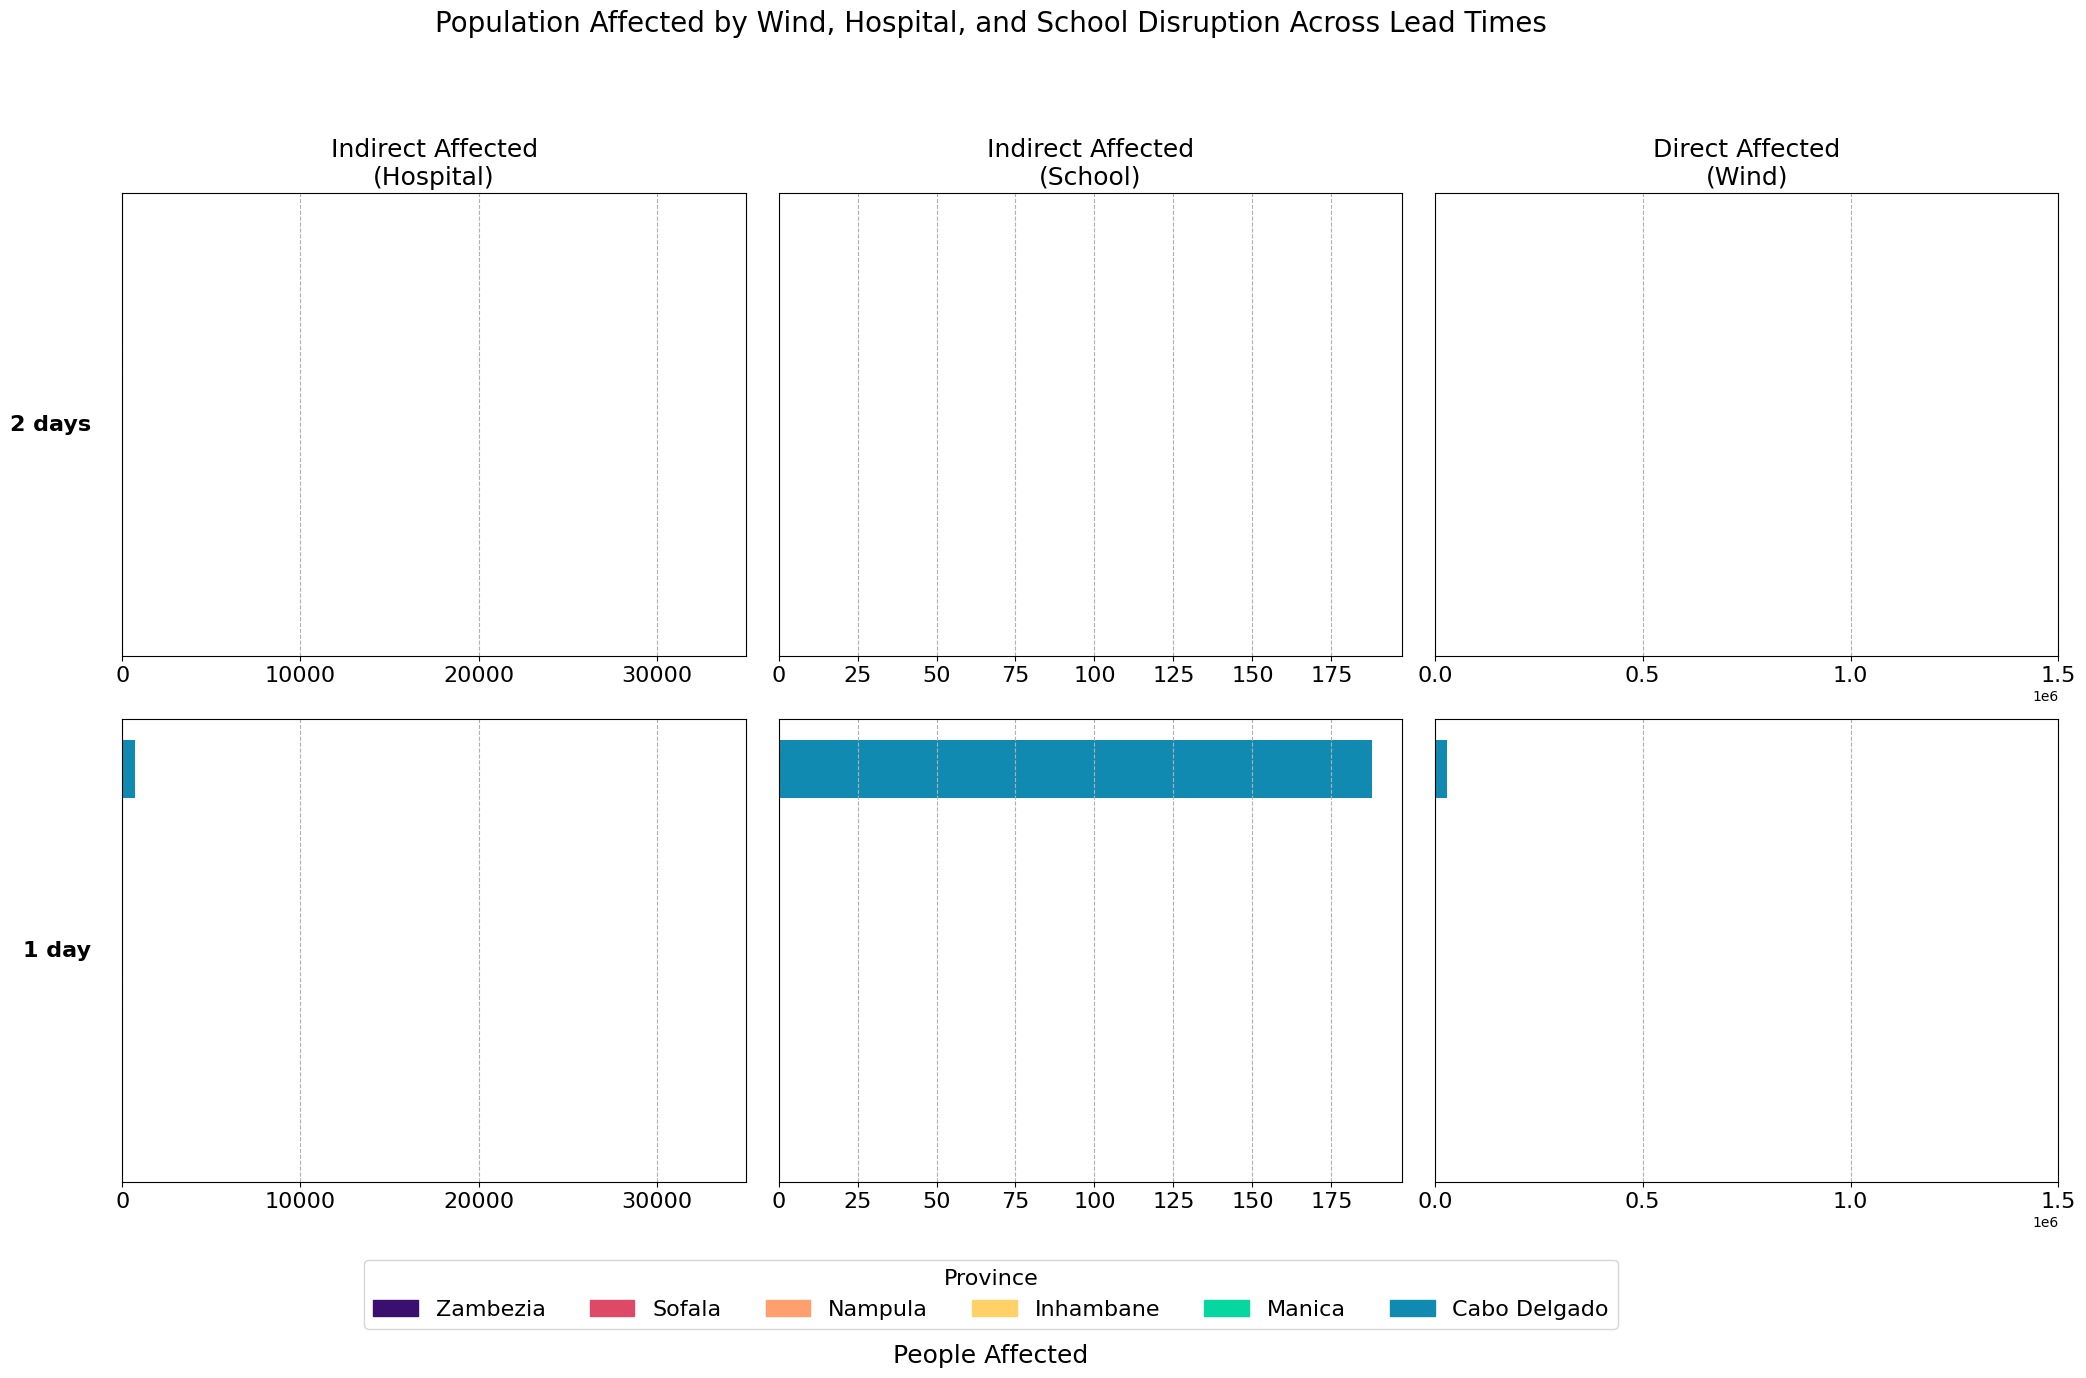

In [60]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch

# Define your lead times
lead_times = ['2 days', '1 day']

# Full list of provinces to plot
provinces = ['Zambezia', 'Sofala', 'Nampula', 'Inhambane', 'Manica','Cabo Delgado']

# Define consistent colors for each province
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0' ,  # teal
    'Cabo Delgado': '#118ab2'   # blue (new addition)
}

# Initialize dictionaries
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}

# Aggregate data by lead time and province
for lt in lead_times:
    # Hospital
    df_h2 = imph2_impp1[lt]
    h2_sums = df_h2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_h2[lt] = h2_sums

    # School
    df_ed2 = ed2_impp1[lt]
    ed2_sums = df_ed2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_ed2[lt] = ed2_sums

    # Wind
    df_p1 = impp1_disrupted[lt]
    p1_sums = df_p1.groupby('NAME_1')['people'].sum()
    leadtime_province_p1[lt] = p1_sums

# Convert to DataFrames
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2 = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)

# Ensure all expected provinces are included (even if 0s)
for df in [df_h2, df_ed2, df_p1]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]  # Reorder columns to match

# Plotting
fig, axes = plt.subplots(nrows=len(lead_times), ncols=3, figsize=(22, 14), sharey=True)

for i, lt in enumerate(lead_times):  # Top-down
    direct_vals = df_h2.loc[lt]
    school_vals = df_ed2.loc[lt]
    wind_vals = df_p1.loc[lt]

    # Hospital disruption (left)
    ax_hosp = axes[i, 0]
    for prov in provinces:
        ax_hosp.barh(prov, direct_vals[prov], color=province_colors[prov])
    ax_hosp.set_xlim(0, 35000)
    ax_hosp.set_xticks([0, 10000, 20000, 30000])
    ax_hosp.tick_params(axis='x', labelsize=16)
    ax_hosp.set_yticks([])
    ax_hosp.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_hosp.set_title("Indirect Affected\n(Hospital)", fontsize=18)
    ax_hosp.text(-0.05, 0.5, lt, transform=ax_hosp.transAxes,
                 fontsize=16, va='center', ha='right', fontweight='bold')

    # School disruption (middle)
    ax_school = axes[i, 1]
    for prov in provinces:
        ax_school.barh(prov, school_vals[prov], color=province_colors[prov])
    ax_school.set_xlim(0, df_ed2.values.max() * 1.05)
    ax_school.tick_params(axis='x', labelsize=16)
    ax_school.set_yticks([])
    ax_school.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_school.set_title("Indirect Affected\n(School)", fontsize=18)

    # Wind impact (right)
    ax_wind = axes[i, 2]
    for prov in provinces:
        ax_wind.barh(prov, wind_vals[prov], color=province_colors[prov])
    ax_wind.set_xlim(0, df_p1.values.max() * 1.05)
    ax_wind.set_xticks([0, 5e5, 1e6, 1.5e6])
    ax_wind.tick_params(axis='x', labelsize=16)
    ax_wind.set_yticks([])
    ax_wind.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_wind.set_title("Direct Affected\n(Wind)", fontsize=18)

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=16, fontsize=16, bbox_to_anchor=(0.5, 0.03))

# Labels and title
fig.supxlabel("People Affected", fontsize=18)
fig.suptitle("Population Affected by Wind, Hospital, and School Disruption Across Lead Times", fontsize=20)

plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])
plt.show()

In [ ]:
### combined--- direct affected and indirect affected!

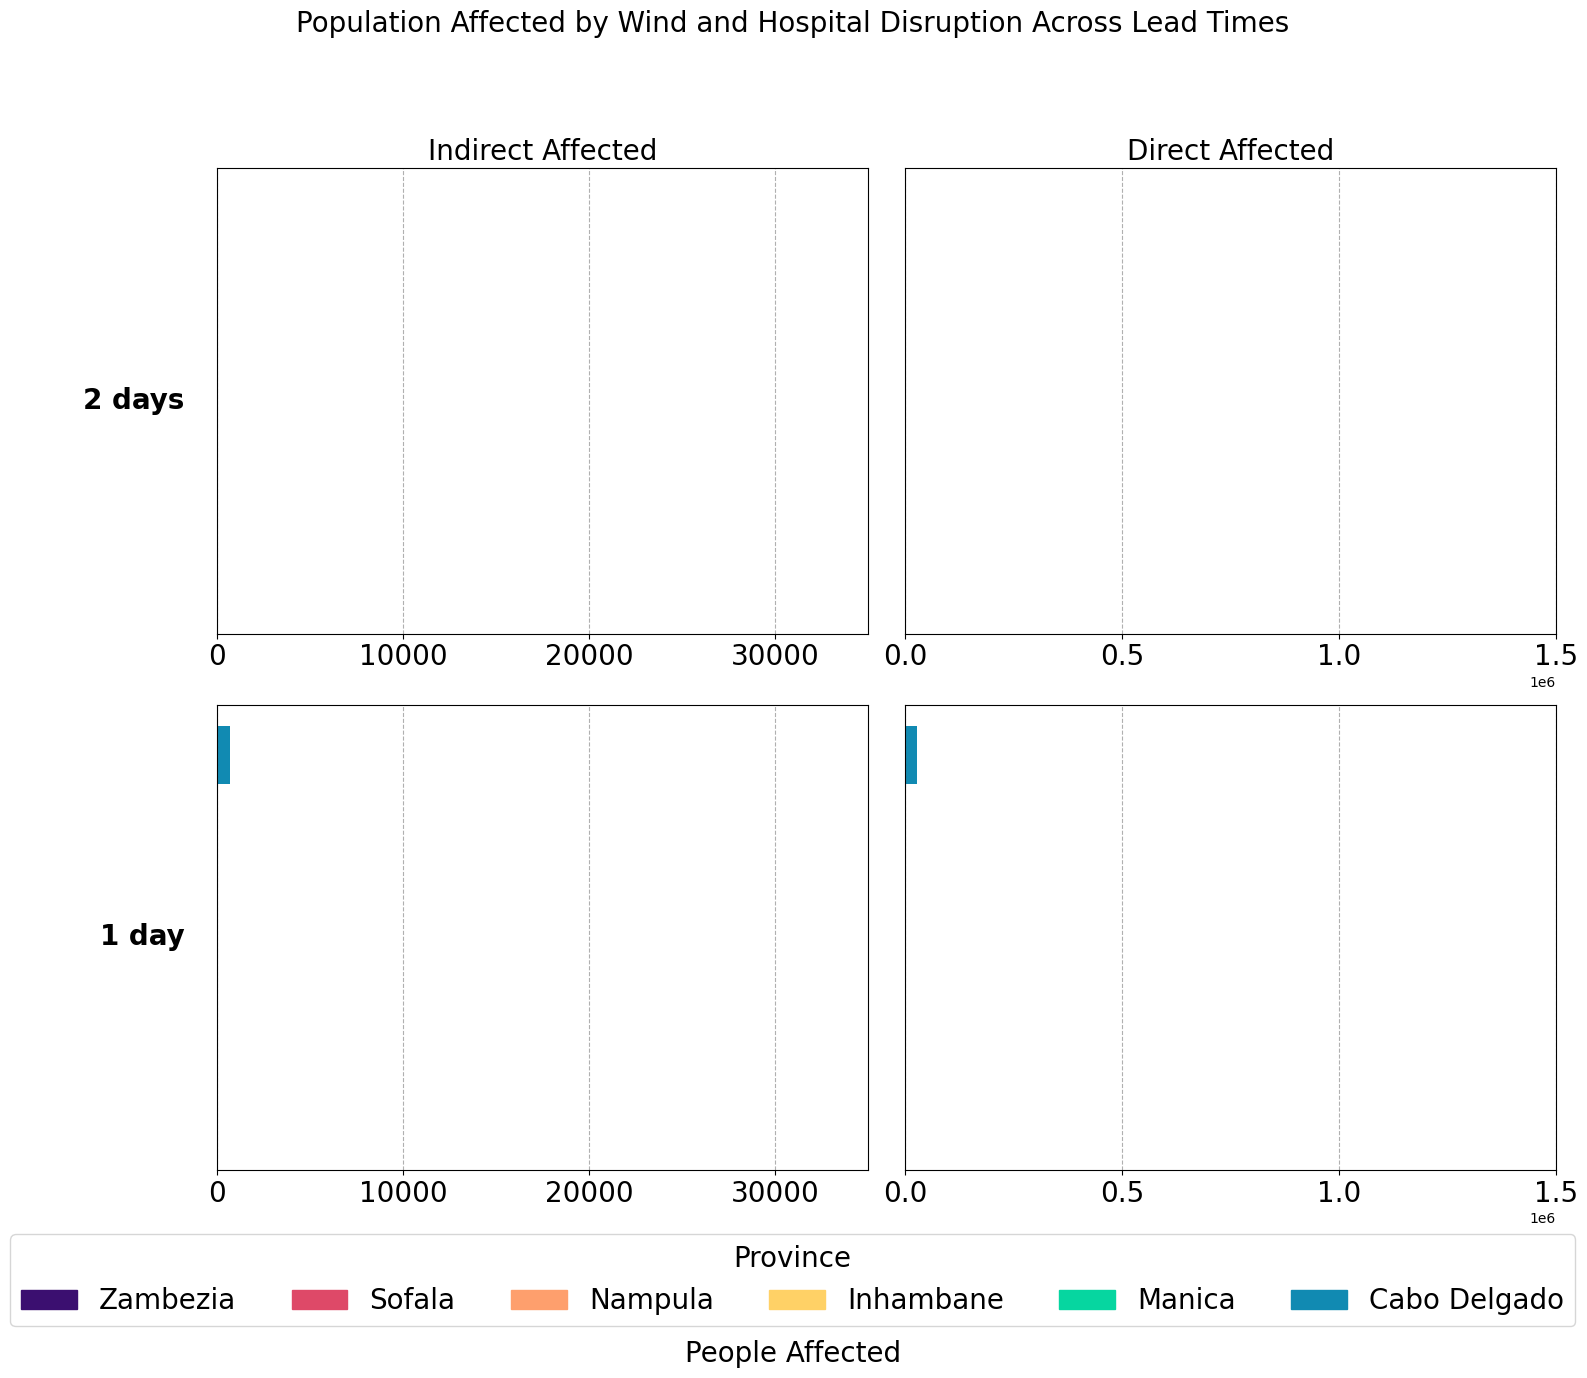

In [61]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch

# Define your lead times
lead_times = ['2 days', '1 day']

# Aggregate data
leadtime_province_h2 = {}
leadtime_province_p1 = {}

for lt in lead_times:
    df_h2 = imph2_impp1[lt]
    h2_sums = df_h2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_h2[lt] = h2_sums

    df_p1 = impp1_disrupted[lt]
    p1_sums = df_p1.groupby('NAME_1')['people'].sum()
    leadtime_province_p1[lt] = p1_sums

# Convert to DataFrames
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)

# Define consistent colors for each province
province_colors = {
    'Zambezia':     '#3b0f70',   # deep purple
    'Sofala':       '#de4968',   # magenta/red
    'Nampula':      '#fe9f6d',   # orange
    'Inhambane':    '#ffd166',   # yellow-orange
    'Manica':       '#06d6a0',   # teal
    'Cabo Delgado': '#118ab2'    # blue
}
provinces = list(province_colors.keys())

# Plotting
fig, axes = plt.subplots(nrows=len(lead_times), ncols=2, figsize=(16, 14), sharey=True)

for i, lt in enumerate(lead_times):  # Top-down
    # Ensure all provinces are present in the Series, fill missing with 0
    direct_vals = df_h2.loc[lt].reindex(provinces, fill_value=0)
    disrupt_vals = df_p1.loc[lt].reindex(provinces, fill_value=0)

    # Direct impact (left)
    ax_direct = axes[i, 0]
    for prov in provinces:
        ax_direct.barh(prov, direct_vals[prov], color=province_colors[prov])
    ax_direct.set_xlim(0, 35000)
    ax_direct.set_xticks([0, 10000, 20000, 30000])
    ax_direct.tick_params(axis='x', labelsize=20)
    ax_direct.set_yticks([])
    ax_direct.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_direct.set_title("Indirect Affected", fontsize=20)
    ax_direct.text(-0.05, 0.5, lt, transform=ax_direct.transAxes,
                   fontsize=20, va='center', ha='right', fontweight='bold')

    # Disrupted access (right)
    ax_disrupt = axes[i, 1]
    for prov in provinces:
        ax_disrupt.barh(prov, disrupt_vals[prov], color=province_colors[prov])
    ax_disrupt.set_xlim(0, df_p1.values.max() * 1.05)
    ax_disrupt.set_xticks([0, 5e5, 1e6, 1.5e6])
    ax_disrupt.tick_params(axis='x', labelsize=20)
    ax_disrupt.set_yticks([])
    ax_disrupt.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_disrupt.set_title("Direct Affected", fontsize=20)

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=20, fontsize=20, bbox_to_anchor=(0.5, 0.03))

# Labels and title
fig.supxlabel("People Affected", fontsize=20)
fig.suptitle("Population Affected by Wind and Hospital Disruption Across Lead Times", fontsize=20)

plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])
plt.show()

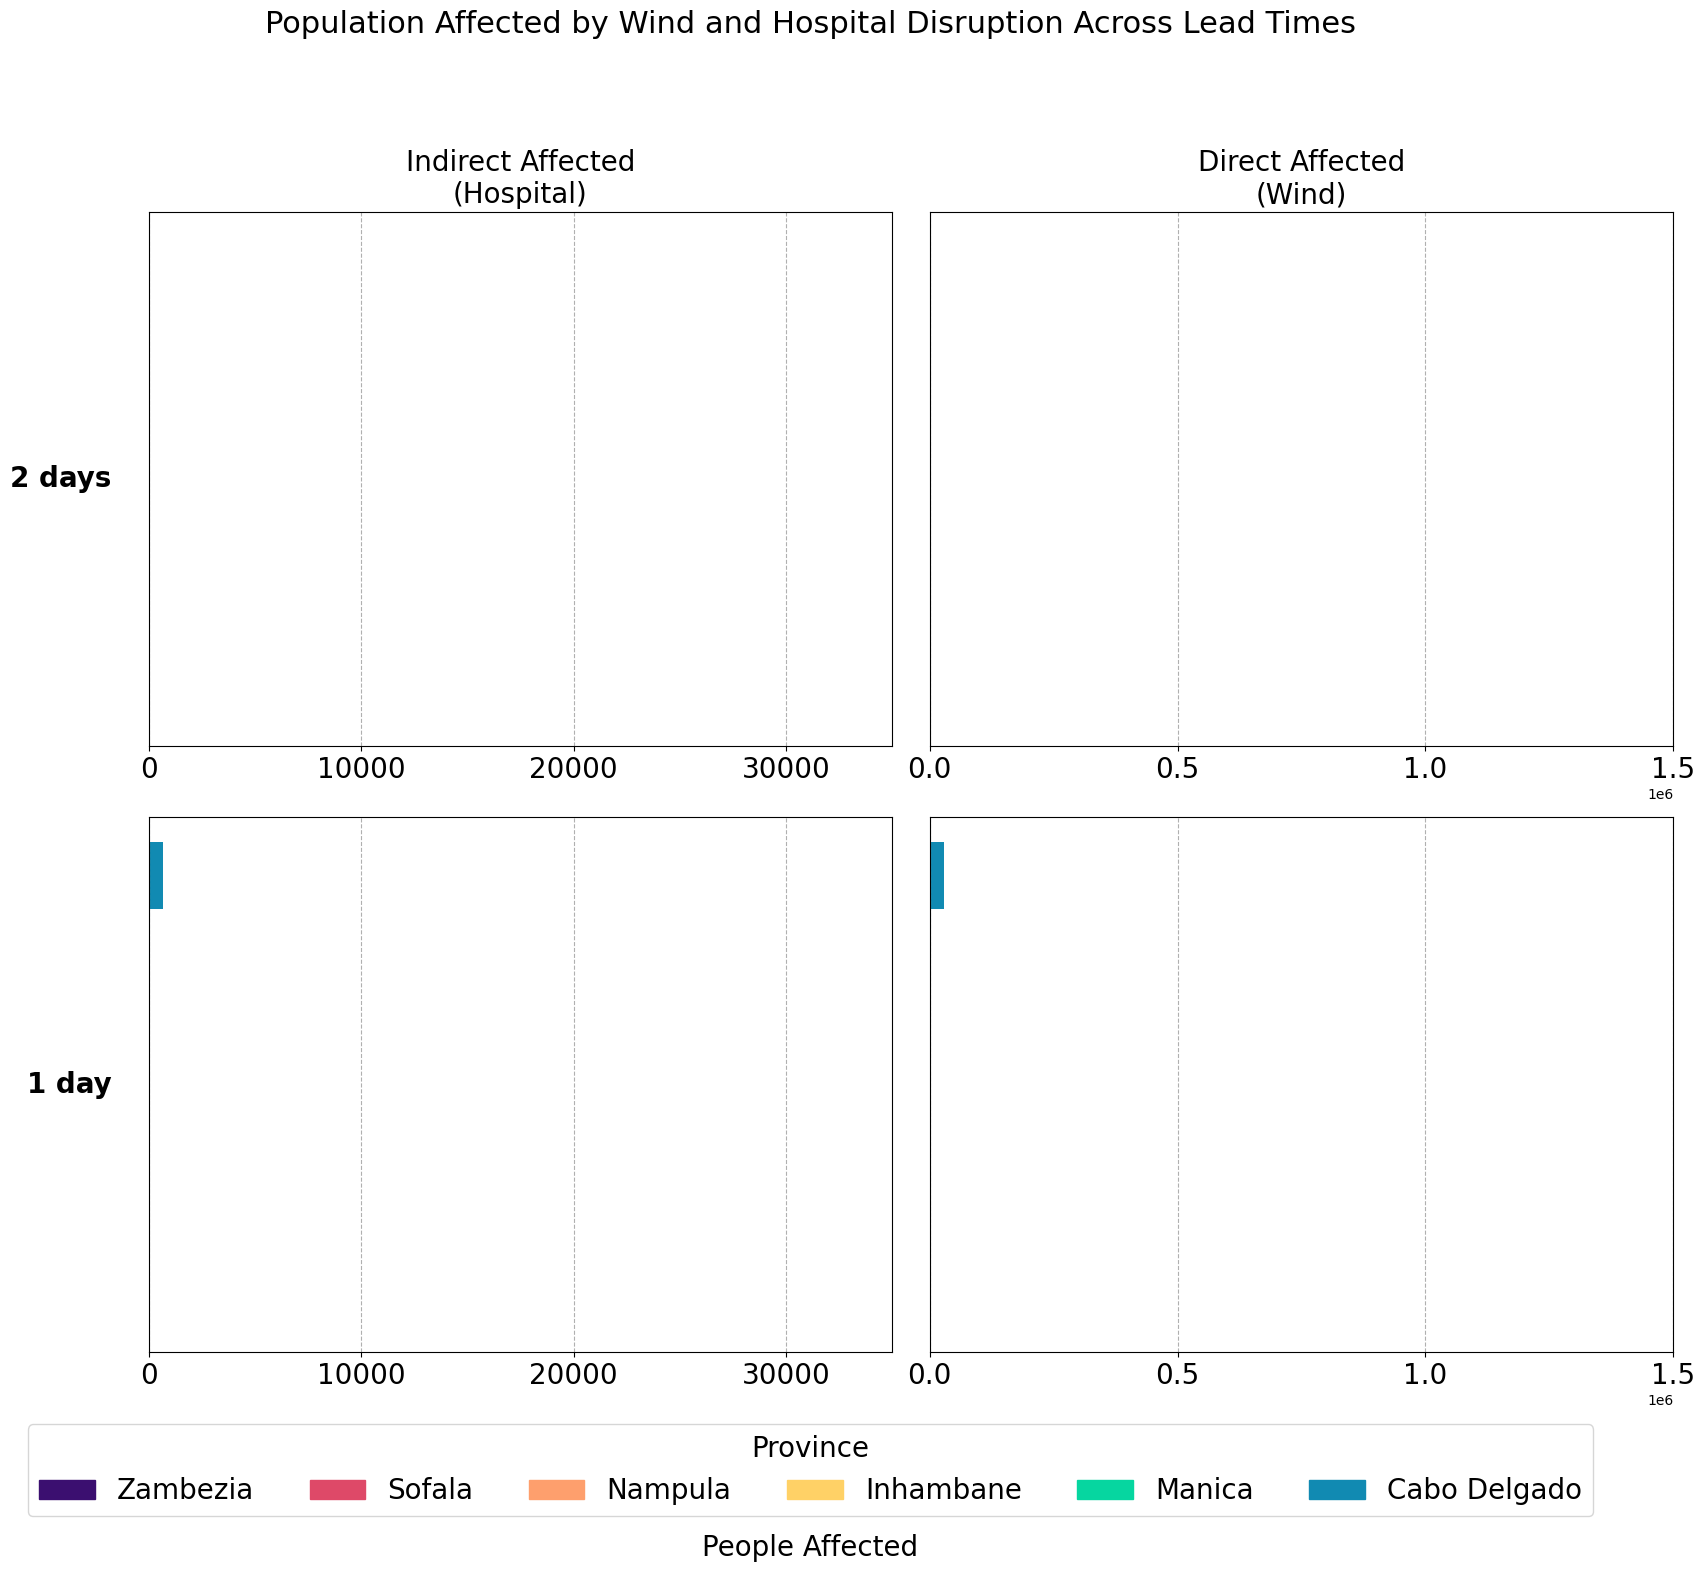

In [62]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch

# Define your lead times
lead_times = ['2 days', '1 day']

# Province colors (extended)
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0',   # teal
    'Cabo Delgado': '#118ab2'    # blue
}
provinces = list(province_colors.keys())

# Aggregate data
leadtime_province_h2 = {}
leadtime_province_p1 = {}

for lt in lead_times:
    df_h2 = imph2_impp1[lt]
    h2_sums = df_h2.groupby('NAME_1')['pp_affected'].sum()
    leadtime_province_h2[lt] = h2_sums

    df_p1 = impp1_disrupted[lt]
    p1_sums = df_p1.groupby('NAME_1')['people'].sum()
    leadtime_province_p1[lt] = p1_sums

# Convert to DataFrames
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)

# Ensure all provinces are present in both DataFrames
for df in [df_h2, df_p1]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]  # Optional: reorder columns if needed

# Plotting
fig, axes = plt.subplots(nrows=len(lead_times), ncols=2, figsize=(18, 16), sharey=True)

for i, lt in enumerate(lead_times):
    hosp_vals = df_h2.loc[lt]
    wind_vals = df_p1.loc[lt]

    # Indirect (hospital)
    ax_hosp = axes[i, 0]
    for prov in provinces:
        ax_hosp.barh(prov, hosp_vals[prov], color=province_colors[prov])
    ax_hosp.set_xlim(0, 35000)
    ax_hosp.set_xticks([0, 10000, 20000, 30000])
    ax_hosp.tick_params(axis='x', labelsize=20)
    ax_hosp.set_yticks([])
    ax_hosp.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_hosp.set_title("Indirect Affected\n(Hospital)", fontsize=20)
    ax_hosp.text(-0.05, 0.5, lt, transform=ax_hosp.transAxes,
                 fontsize=20, va='center', ha='right', fontweight='bold')

    # Direct (wind)
    ax_wind = axes[i, 1]
    for prov in provinces:
        ax_wind.barh(prov, wind_vals[prov], color=province_colors[prov])
    ax_wind.set_xlim(0, df_p1.values.max() * 1.05)
    ax_wind.set_xticks([0, 5e5, 1e6, 1.5e6])
    ax_wind.tick_params(axis='x', labelsize=20)
    ax_wind.set_yticks([])
    ax_wind.grid(axis='x', linestyle='--', alpha=1)
    if i == 0:
        ax_wind.set_title("Direct Affected\n(Wind)", fontsize=20)

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=20, fontsize=20, bbox_to_anchor=(0.5, 0.03))

# Labels and title
fig.supxlabel("People Affected", fontsize=20)
fig.suptitle("Population Affected by Wind and Hospital Disruption Across Lead Times", fontsize=22)

plt.tight_layout(rect=[0.05, 0.07, 1, 0.93])
plt.show()

In [ ]:
###Combined with all infrastructure 

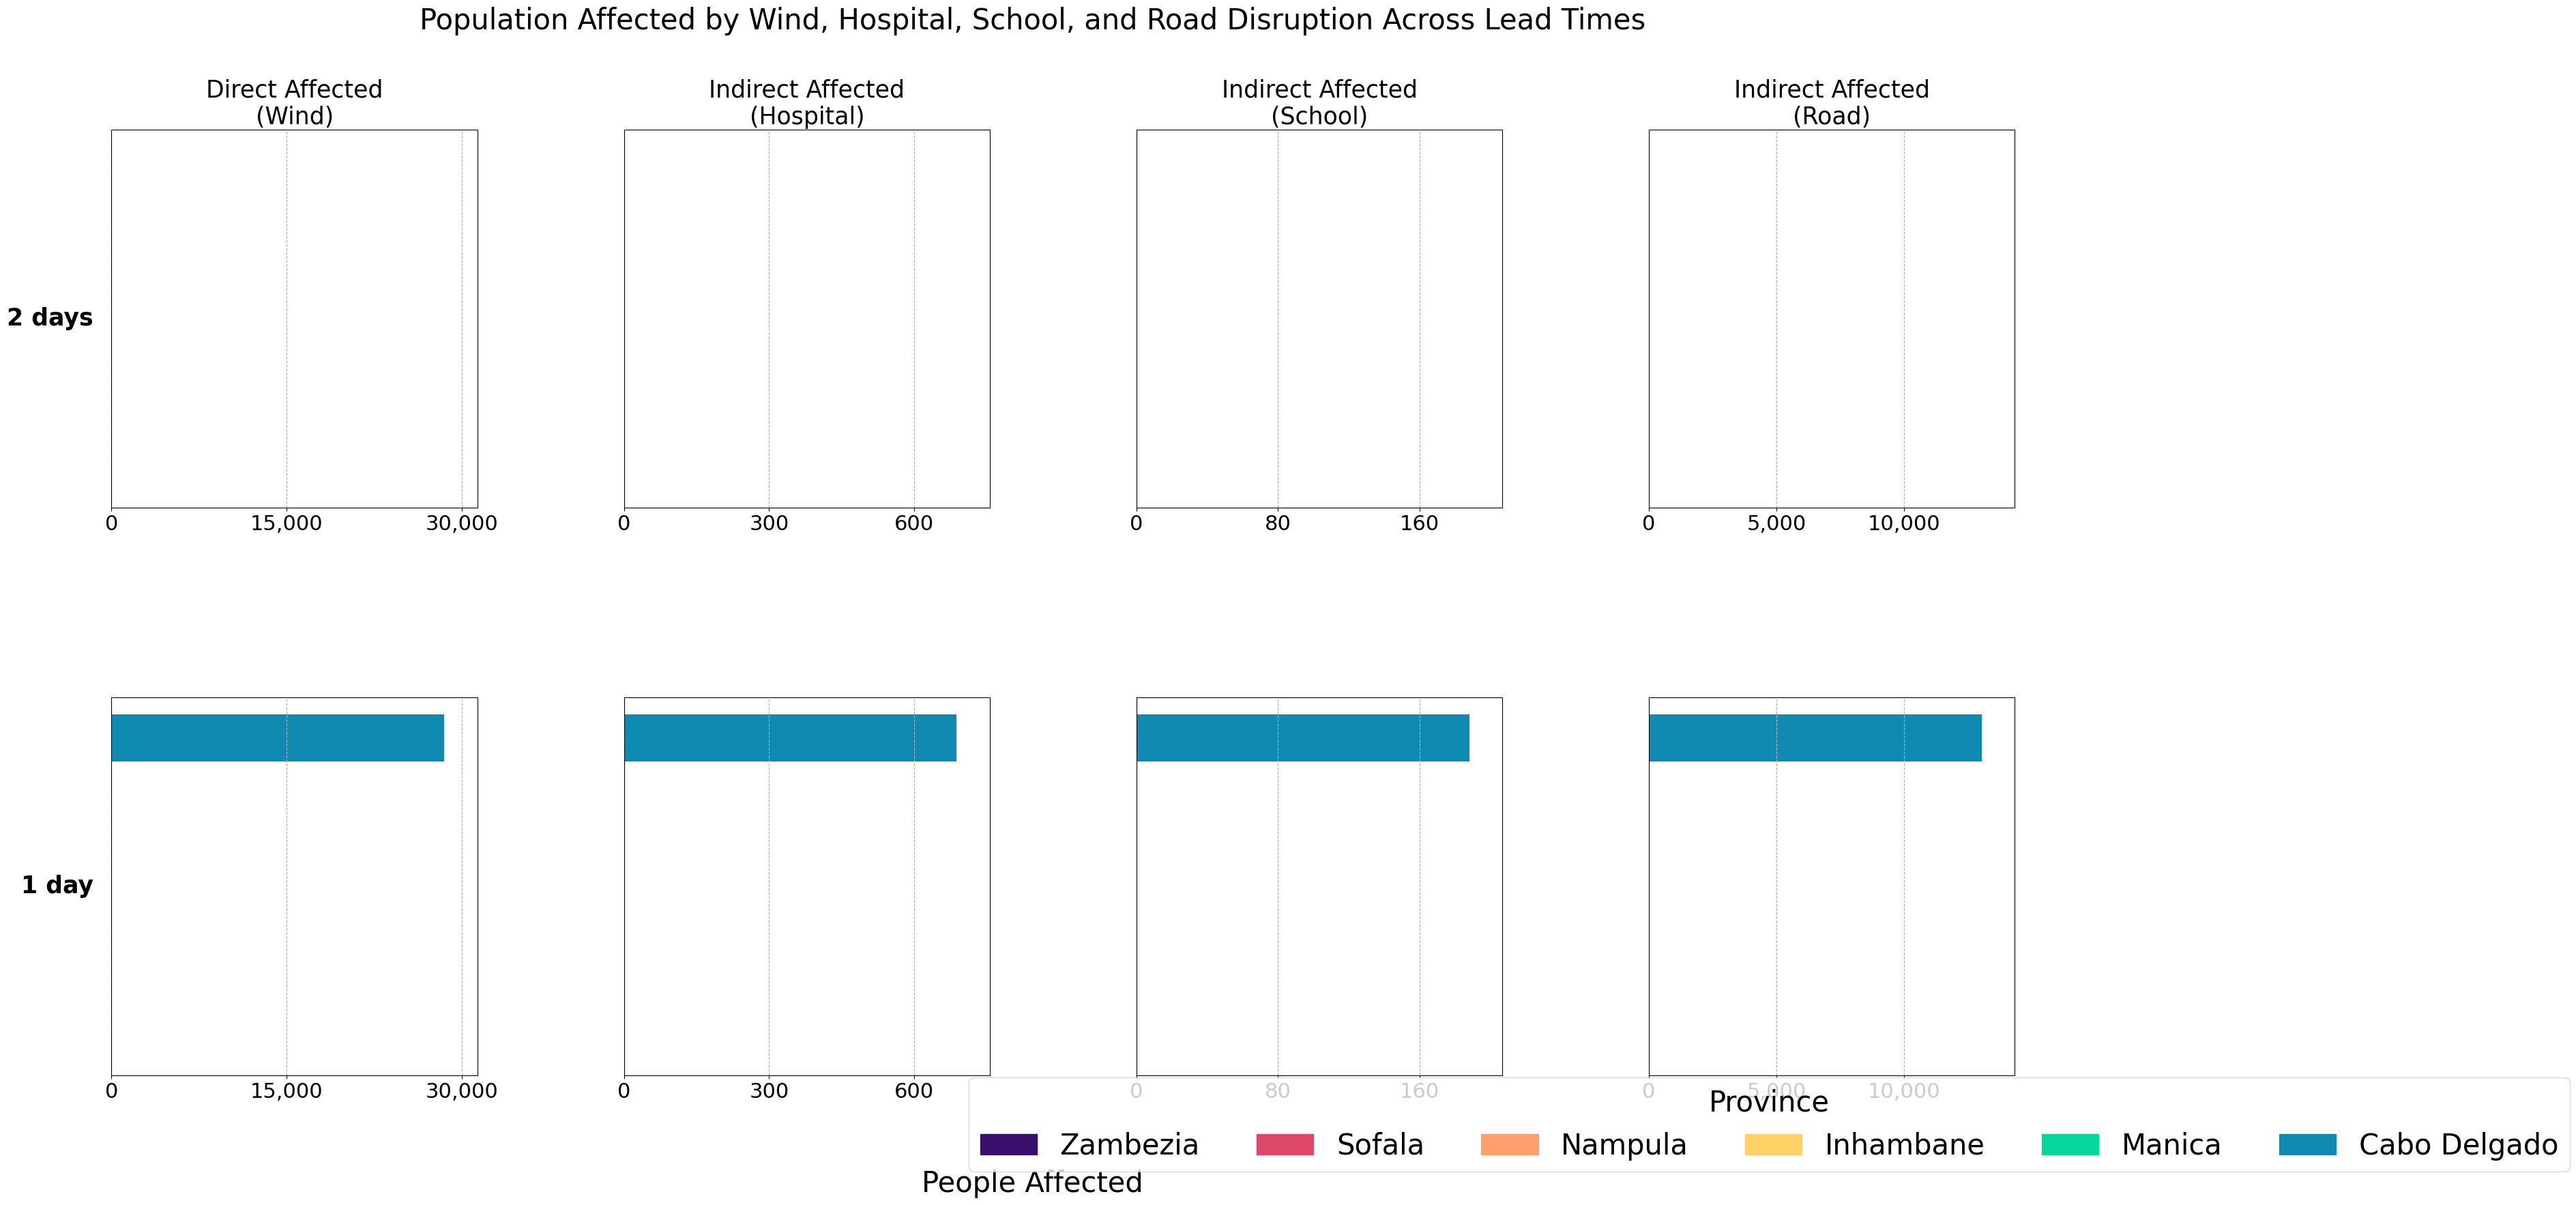

In [63]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and updated province colors
lead_times = ['2 days', '1 day']
province_colors = {
    'Zambezia':  '#3b0f70',
    'Sofala':    '#de4968',
    'Nampula':   '#fe9f6d',
    'Inhambane': '#ffd166',
    'Manica':    '#06d6a0',
    'Cabo Delgado': '#118ab2'    # blue
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2 = imph2_impp1[lt]
    leadtime_province_h2[lt] = df_h2.groupby('NAME_1')['pp_affected'].sum()

    df_ed2 = ed2_impp1[lt]
    leadtime_province_ed2[lt] = df_ed2.groupby('NAME_1')['pp_affected'].sum()

    df_p1 = impp1_disrupted[lt]
    leadtime_province_p1[lt] = df_p1.groupby('NAME_1')['people'].sum()

    df_rd2 = rd2_disrupted_impp1[lt]
    leadtime_province_rd2[lt] = df_rd2.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and ensure all provinces are included
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2 = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2 = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Ensure consistent province order and fill missing columns
for df in [df_h2, df_ed2, df_p1, df_rd2]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]  # Reorder columns if needed

# Create figure and GridSpec layout
fig = plt.figure(figsize=(36, 18))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

for i, lt in enumerate(lead_times):
    wind_vals = df_p1.loc[lt]
    hosp_vals = df_h2.loc[lt]
    school_vals = df_ed2.loc[lt]
    road_vals = df_rd2.loc[lt]

    for j, (vals, title, df_max) in enumerate([
        (wind_vals, "Direct Affected\n(Wind)", df_p1.values.max()),
        (hosp_vals, "Indirect Affected\n(Hospital)", df_h2.values.max()),
        (school_vals, "Indirect Affected\n(School)", df_ed2.values.max()),
        (road_vals, "Indirect Affected\n(Road)", df_rd2.values.max())
    ]):
        ax = fig.add_subplot(gs[i, j])
        for prov in provinces:
            ax.barh(prov, vals[prov], color=province_colors[prov])
        ax.set_xlim(0, df_max * 1.1 if df_max > 0 else 1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=22)
        ax.xaxis.get_offset_text().set_fontsize(22)
        ax.set_yticks([])
        ax.grid(axis='x', linestyle='--', alpha=1)
        if i == 0:
            ax.set_title(title, fontsize=25)
        if j == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, j] = ax

# Add legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=30, fontsize=30, bbox_to_anchor=(0.8, 0.02))

# Add global labels
fig.supxlabel("People Affected", fontsize=30)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=30)

# Show plot
plt.show()

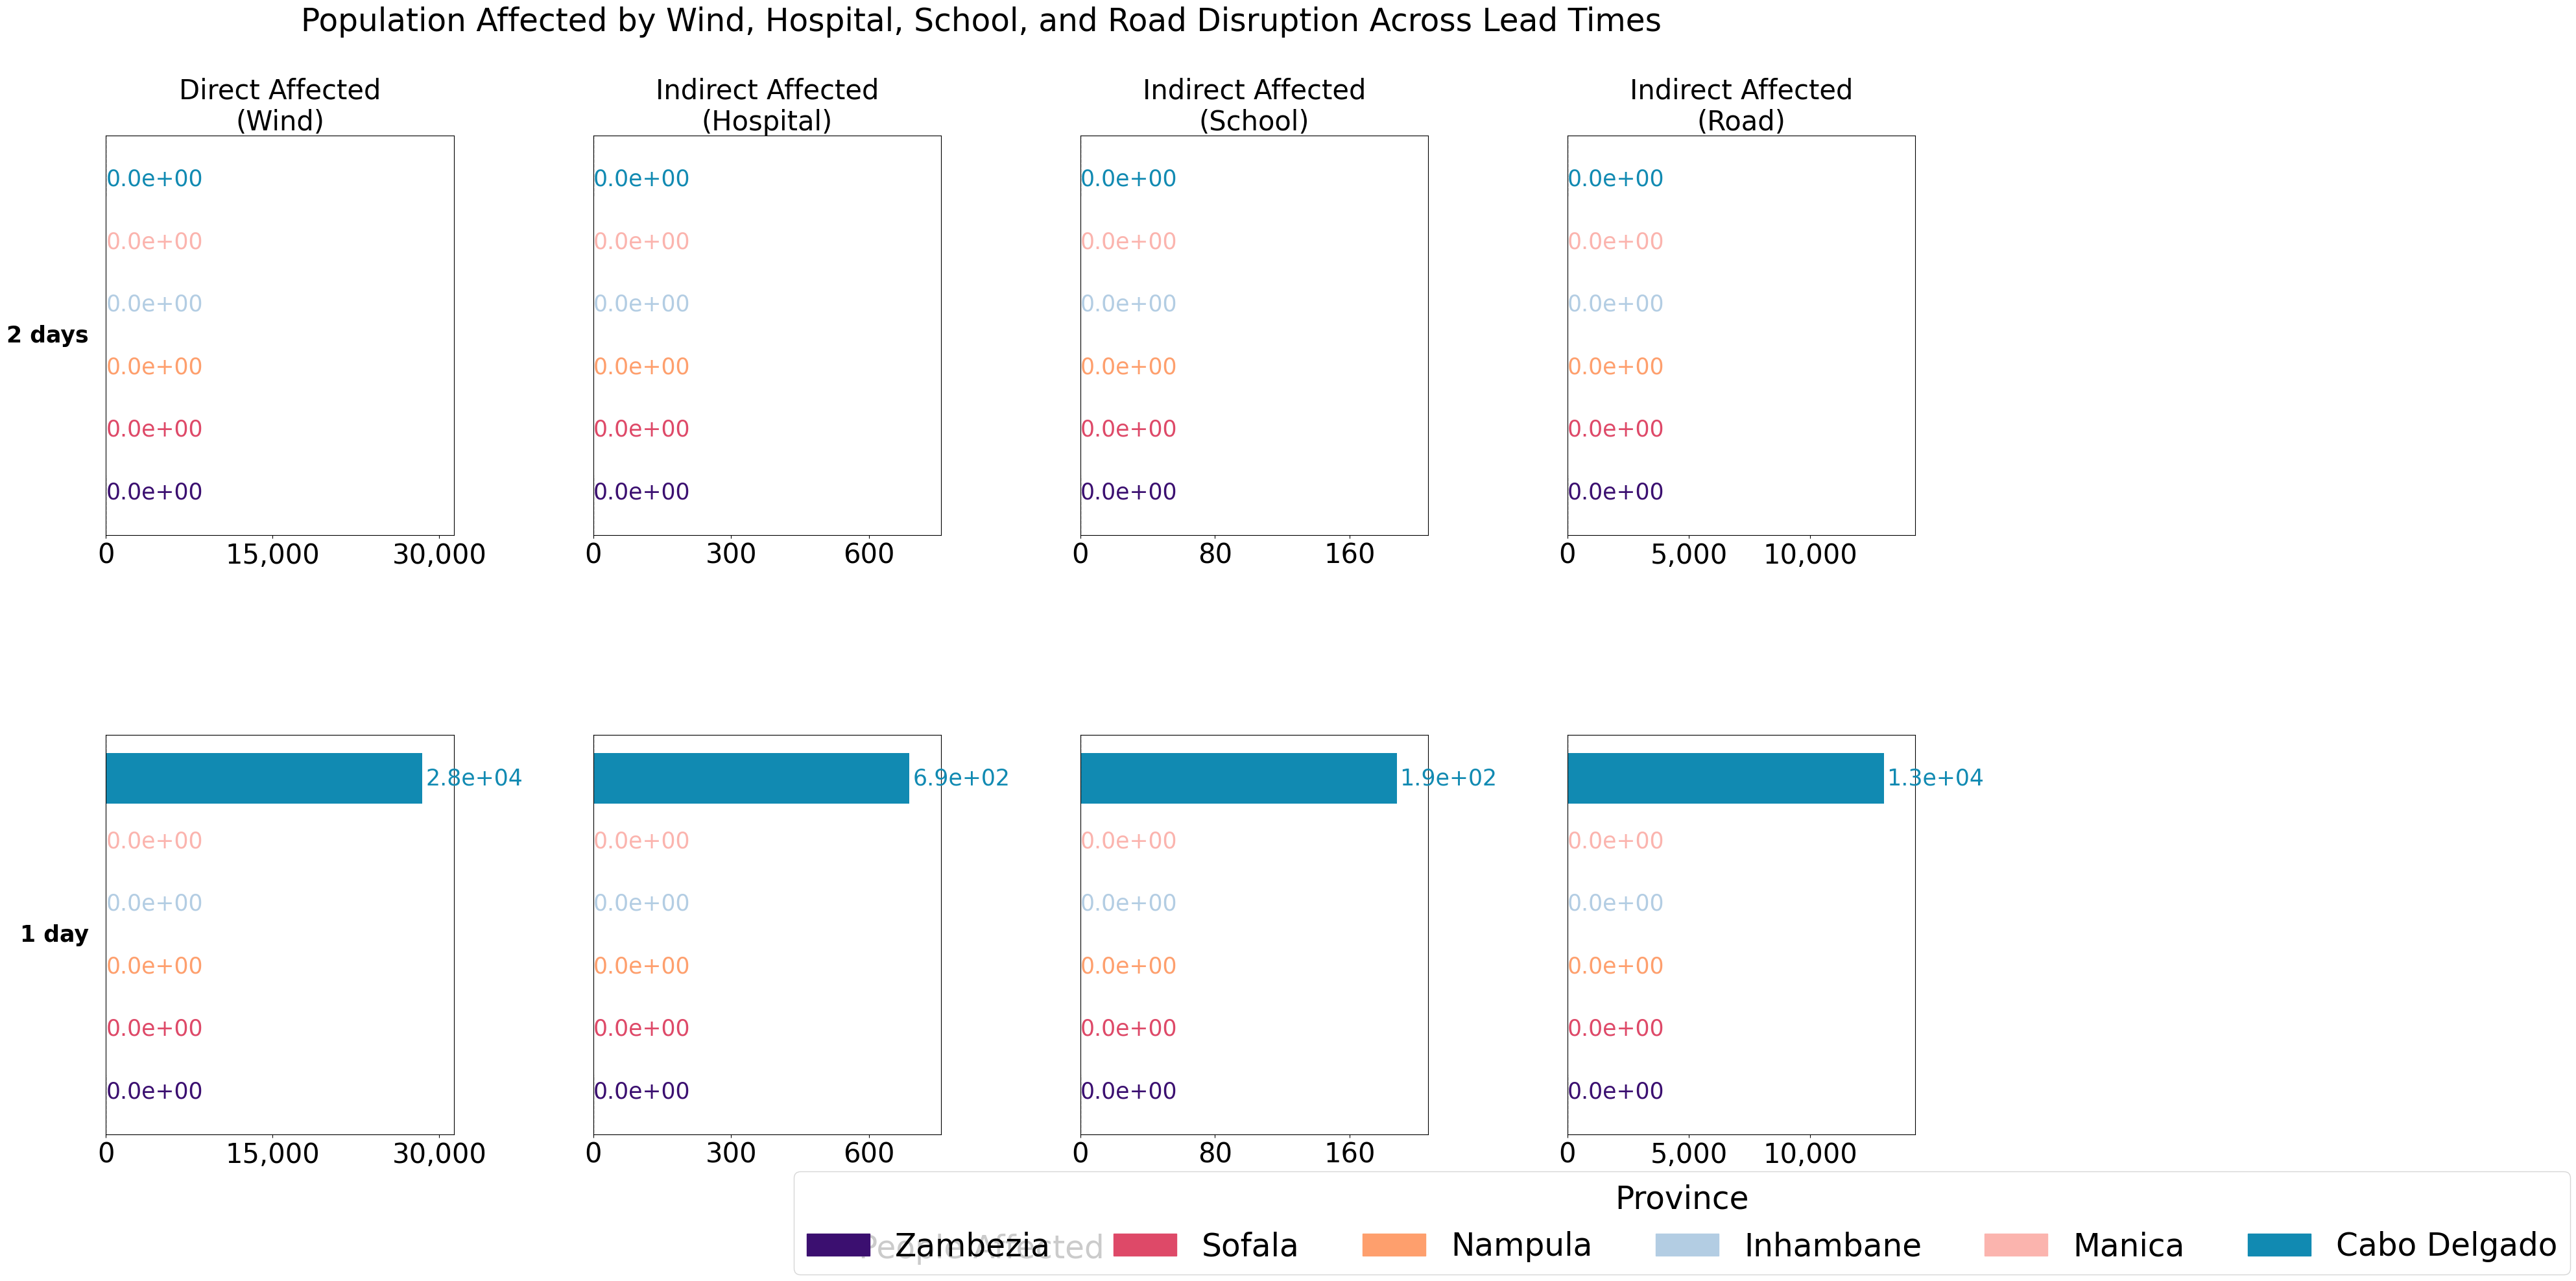

In [64]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and updated province colors
lead_times = ['2 days', '1 day']
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#b3cde3',  # muted steel blue pastel
    'Manica':    '#fbb4ae',  # soft rose pink pastel
    'Cabo Delgado': '#118ab2'
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2 = imph2_impp1[lt]
    leadtime_province_h2[lt] = df_h2.groupby('NAME_1')['pp_affected'].sum()

    df_ed2 = ed2_impp1[lt]
    leadtime_province_ed2[lt] = df_ed2.groupby('NAME_1')['pp_affected'].sum()

    df_p1 = impp1_disrupted[lt]
    leadtime_province_p1[lt] = df_p1.groupby('NAME_1')['people'].sum()

    df_rd2 = rd2_disrupted_impp1[lt]
    leadtime_province_rd2[lt] = df_rd2.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and ensure all provinces are present
df_h2 = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2 = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1 = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2 = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Ensure all provinces exist in each DataFrame and are in correct order
for df in [df_h2, df_ed2, df_p1, df_rd2]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]

# Create figure and GridSpec layout
fig = plt.figure(figsize=(36, 20))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

# Helper: Draw vertical bar-end line and text
def draw_bar_end_line(ax, value, y, color):
    ax.axvline(x=value, ymin=y-0.15, ymax=y+0.15, color='gray', linestyle='--', linewidth=1)
    ax.text(value * 1.01, y, f"{value:.1e}", fontsize=25, va='center', ha='left', color=color)

# Plotting
for i, lt in enumerate(lead_times):
    wind_vals = df_p1.loc[lt]
    hosp_vals = df_h2.loc[lt]
    school_vals = df_ed2.loc[lt]
    road_vals = df_rd2.loc[lt]

    for col, (vals, title, maxval) in enumerate([
        (wind_vals,   "Direct Affected\n(Wind)",    df_p1.values.max()),
        (hosp_vals,   "Indirect Affected\n(Hospital)", df_h2.values.max()),
        (school_vals, "Indirect Affected\n(School)",   df_ed2.values.max()),
        (road_vals,   "Indirect Affected\n(Road)",     df_rd2.values.max())
    ]):
        ax = fig.add_subplot(gs[i, col])
        for j, prov in enumerate(provinces):
            val = vals[prov]
            ax.barh(j, val, color=province_colors[prov])
            draw_bar_end_line(ax, val, j, province_colors[prov])

        ax.set_xlim(0, maxval * 1.1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=30)
        ax.set_yticks([])
        ax.grid(False)
        if i == 0:
            ax.set_title(title, fontsize=30)
        if col == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, col] = ax

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=35, fontsize=35, bbox_to_anchor=(0.8, -0.01))

# Global axis and title
fig.supxlabel("People Affected", fontsize=35)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=35)

# Save high-resolution figure
#fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Idai/direct_indirect_people_IDAI", dpi=800, bbox_inches='tight')

# Show plot
plt.show()

In [ ]:
## then we will calculate it when we use categorization 1 cat 

In [236]:
### 
def calculate_direct_and_indirect_impacts(
    imph2, imps2, impp1, rd2_51ens,
    exp_rd2_gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
):
    # 1. Disrupted hospitals
    disrupted_hospitals = get_disrupted_exposures_and_ensemble(imph2, threshold=0.20, min_members=5, mode="above")
    disrupted_hospitals_copy = disrupted_hospitals.copy()
    
    # 2. Disrupted schools
    disrupted_schools = get_disrupted_exposures_and_ensemble(imps2, threshold=0.20, min_members=5, mode="above")
    disrupted_schools_copy = disrupted_schools.copy()
    
    # 3. Disrupted infrastructure (e.g. wind): add population + region
    impp1_disrupted = get_disrupted_exposures_and_ensemble(impp1, threshold=0.20, min_members=5, mode="above")
    impp1_disrupted = add_population_and_region_to_disrupted(impp1_disrupted, gdf_worldpop_MOZ.gdf, gadm_MOZ_gdf)
    impp1_disrupted_copy = impp1_disrupted.copy()
    
    # 4. Disrupted roads
    rd2_mimpact = join_road_exp_51ens(rd2_51ens, exp_rd2_gdf)
    mimpact_cols_scale(rd2_mimpact, 500.0)
    rd2_disrupted = get_disrupted_road(rd2_mimpact, threshold=0.20, min_members=5, mode="above")
    rd2_disrupted = add_geometry_to_disrupted_roads(rd2_disrupted, gdf_roads_MOZ)
    rd2_disrupted_copy = rd2_disrupted.copy()
    
    # 5. Indirect impacts
    imph2_impp1 = cal_nearestpop_to_infrastructure(disrupted_hospitals_copy, impp1_disrupted_copy)
    ed2_impp1 = cal_nearestpop_to_infrastructure(disrupted_schools_copy, impp1_disrupted_copy)
    rd2_disrupted_impp1 = calc_pp_byroaddisrup_5ens(rd2_disrupted_copy, impp1_disrupted_copy, radius_km=2)
    rd2_disrupted_impp1 = assign_province_to_roads(rd2_disrupted_impp1, gadm_MOZ)
    
    return imph2_impp1, ed2_impp1, impp1_disrupted_copy, rd2_disrupted_impp1

In [237]:
imph1_impp1_cat, ed1_impp1_cat, impp1_disrupted_copy_cat, rd1_disrupted_impp1_cat = calculate_direct_and_indirect_impacts(
    imph1_cat, ed1_cat, impp1, rd1_51ens_cat,
    exp_dict_cat['exp_rd1_MOZ'].gdf, gdf_roads_MOZ,
    gdf_worldpop_MOZ, gadm_MOZ_gdf, gadm_MOZ
)

/scratch/tmp.33780607.gespejo/ipykernel_37506/2390560494.py:28: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  centroids = gadm_MOZ_gdf.geometry.centroid


 224493 unmatched points in impp1_MOZ_Idai_20190310120000 — assigning nearest NAME_1 using KDTree...
 217984 unmatched points in impp1_MOZ_Idai_20190311120000 — assigning nearest NAME_1 using KDTree...
 158554 unmatched points in impp1_MOZ_Idai_20190312120000 — assigning nearest NAME_1 using KDTree...
 117481 unmatched points in impp1_MOZ_Idai_20190313120000 — assigning nearest NAME_1 using KDTree...
 41304 unmatched points in impp1_MOZ_Idai_20190314120000 — assigning nearest NAME_1 using KDTree...

🔍 Starting nearest population match for 5 lead times...

➡️  Processing: imph1_MOZ_Idai_20190310120000 | impp1_MOZ_Idai_20190310120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_Idai_20190310120000

➡️  Processing: imph1_MOZ_Idai_20190311120000 | impp1_MOZ_Idai_20190311120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_Idai_20190311120000

➡️  Processing: imph1_MOZ_Idai_20190312120000 | impp1_MOZ_Idai_20190312120000
 ✅ SUCCESS: Population + NAME_1 assigned to imph1_MOZ_

In [241]:
imph1_impp1_cat_dict_rename = {
    'imph1_MOZ_Idai_20190310120000': '4 days',
    'imph1_MOZ_Idai_20190311120000': '3 days',
    'imph1_MOZ_Idai_20190312120000': '2 days',
    'imph1_MOZ_Idai_20190313120000': '1 day',
    'imph1_MOZ_Idai_20190314120000': 'landfall',
}
# Rename keys using rename_dict
imph1_impp1_cat = {imph1_impp1_cat_dict_rename.get(k, k): v for k, v in imph1_impp1_cat.items() if k in imph1_impp1_cat_dict_rename}

In [243]:
ed1_impp1_cat_dict_rename = {
    'ed1_MOZ_Idai_20190310120000': '4 days',
    'ed1_MOZ_Idai_20190311120000': '3 days',
    'ed1_MOZ_Idai_20190312120000': '2 days',
    'ed1_MOZ_Idai_20190313120000': '1 day',
    'ed1_MOZ_Idai_20190314120000': 'landfall',
}
# Rename keys using rename_dict
ed1_impp1_cat = {ed1_impp1_cat_dict_rename.get(k, k): v for k, v in ed1_impp1_cat.items() if k in ed1_impp1_cat_dict_rename}

In [245]:
impp1_cat_dict_rename = {
    'impp1_MOZ_Idai_20190310120000': '5 days',
    'impp1_MOZ_Idai_20190311120000': '4 days',
    'impp1_MOZ_Idai_20190312120000': '3 days',
    'impp1_MOZ_Idai_20190313120000': '2 days',
    'impp1_MOZ_Idai_20190314120000': '1 day',
}
# Rename keys using rename_dict
impp1_disrupted_copy_cat = {impp1_cat_dict_rename.get(k, k): v for k, v in impp1_disrupted_copy_cat.items() if k in impp1_cat_dict_rename}

In [247]:
rd1_impp1_cat_dict_rename = {
    '20190310120000': '4 days',
    '20190311120000': '3 days',
    '20190312120000': '2 days',
    '20190313120000': '1 day',
    '20190314120000': 'landfall',
}
# Rename keys using rename_dict
rd1_disrupted_impp1_cat = {rd1_impp1_cat_dict_rename.get(k, k): v for k, v in rd1_disrupted_impp1_cat.items() if k in rd1_impp1_cat_dict_rename}

In [ ]:
### Results with categories calculated for the impacts 

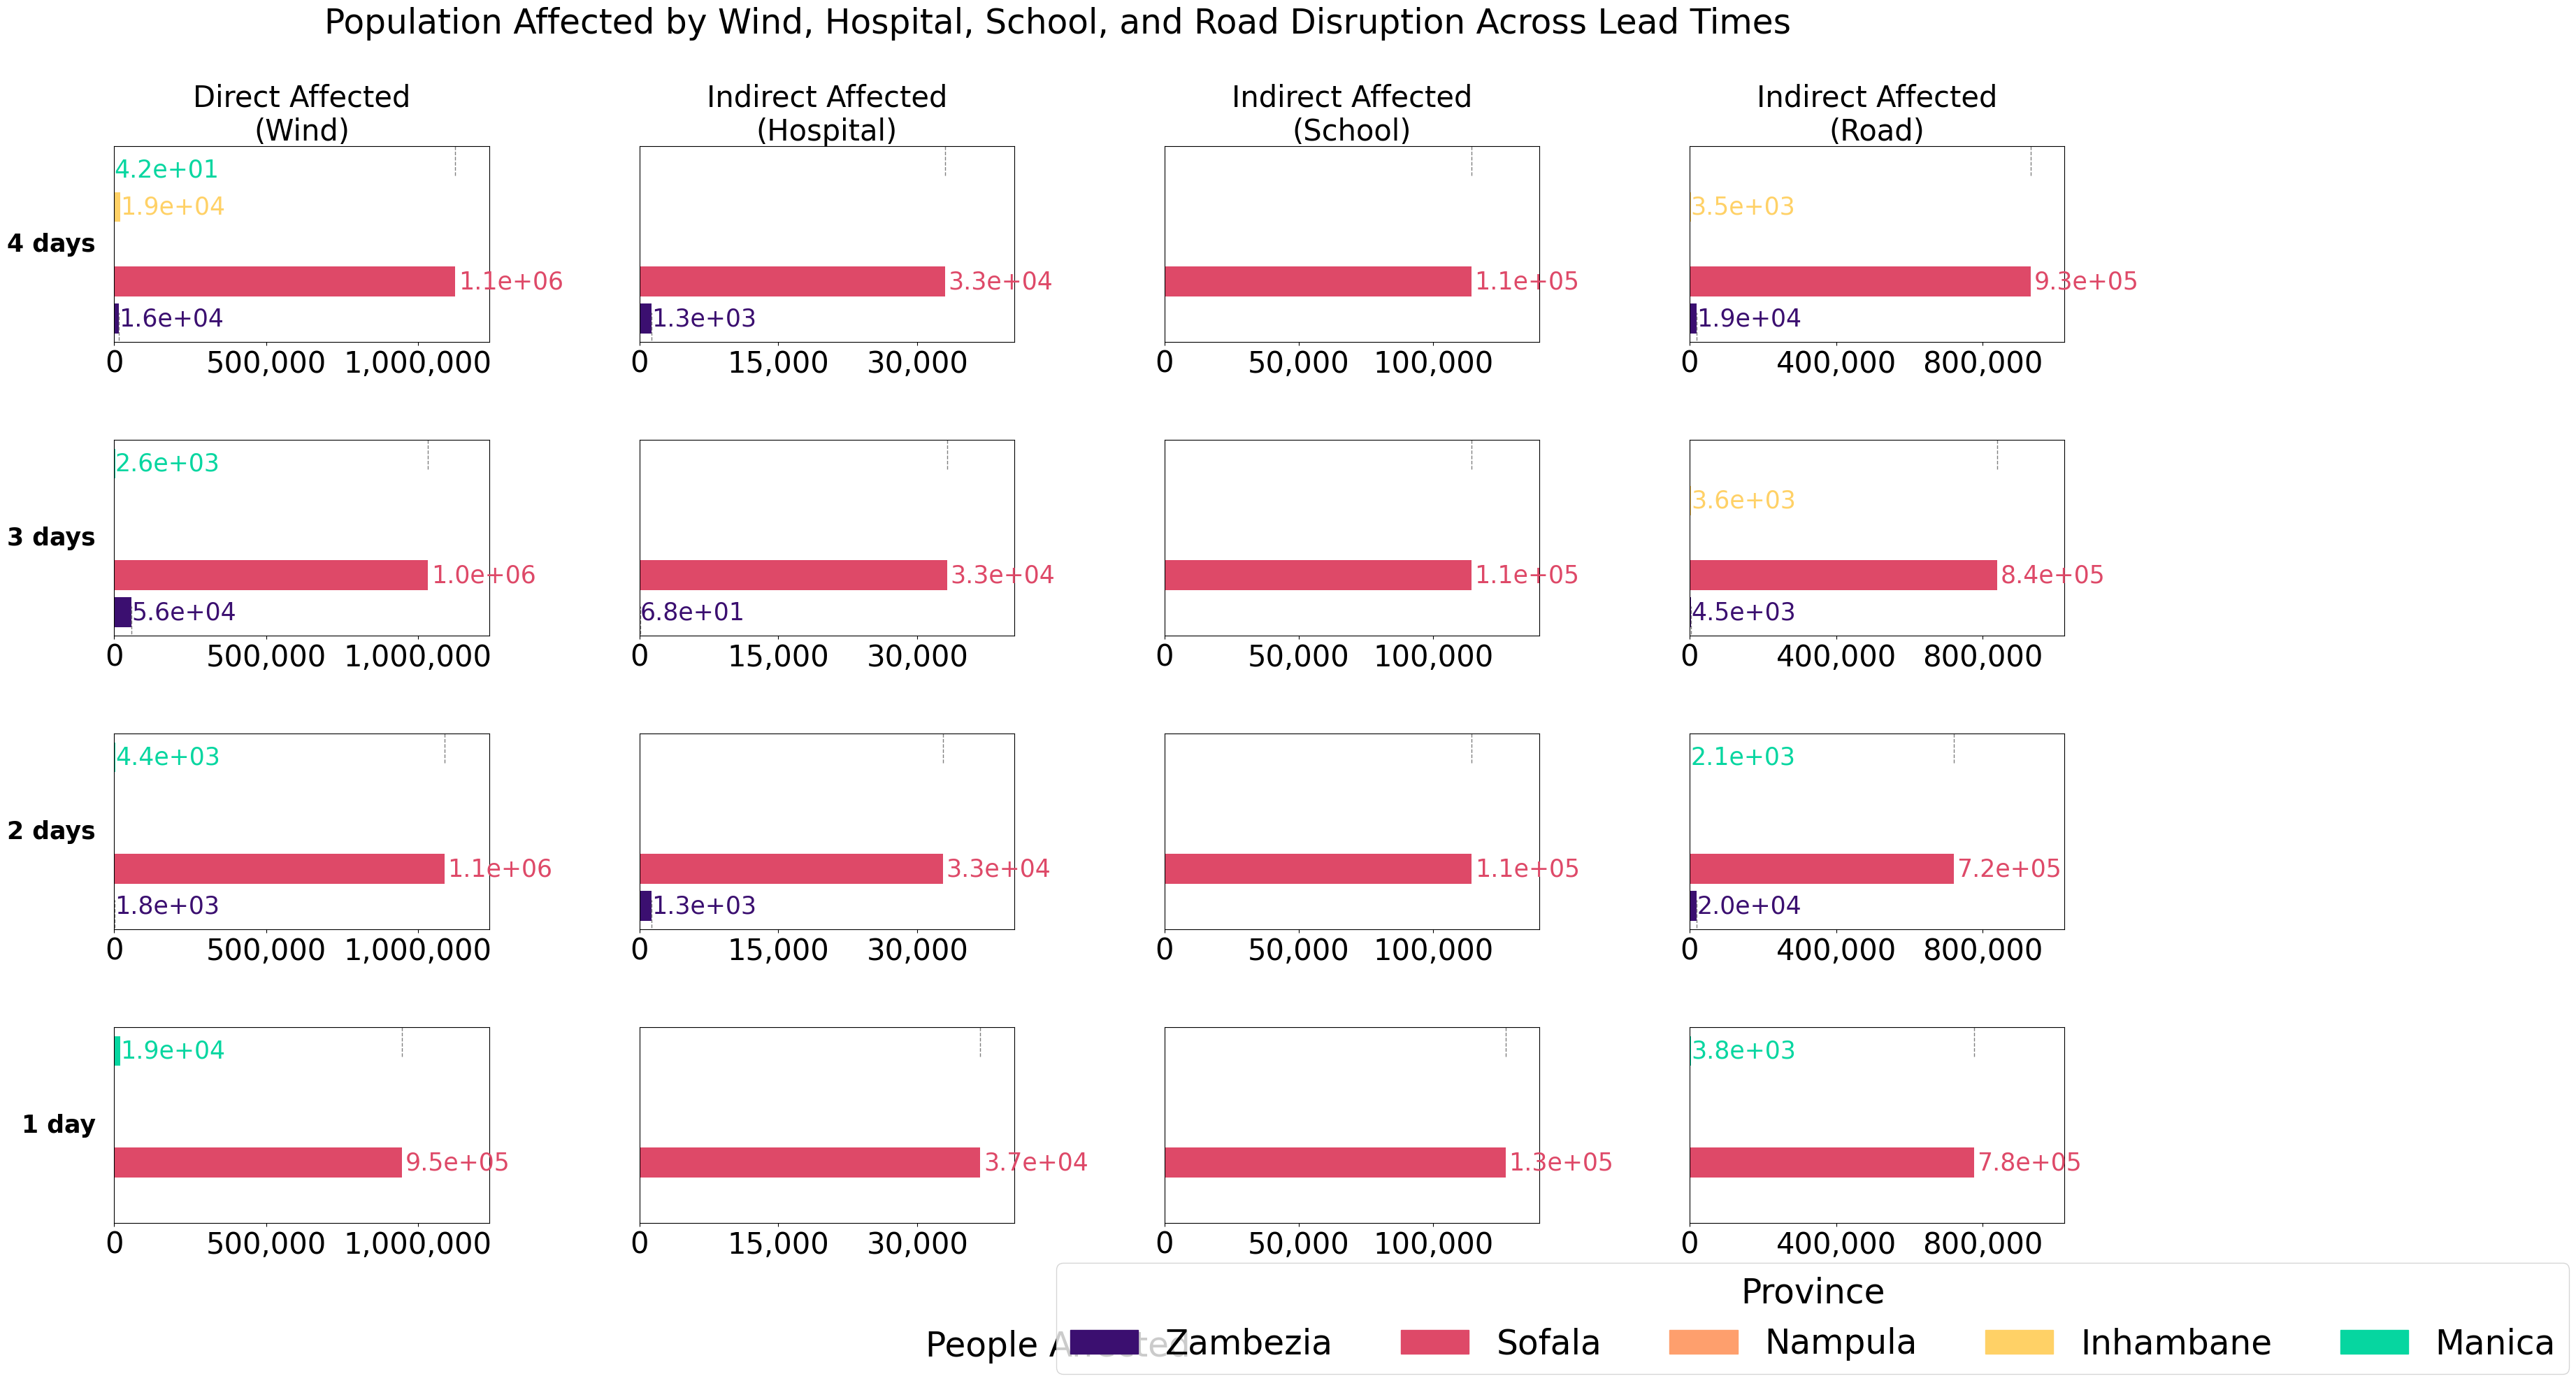

In [248]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['4 days', '3 days', '2 days', '1 day']
province_colors = {
    'Zambezia':  '#3b0f70',  # deep purple
    'Sofala':    '#de4968',  # magenta/red
    'Nampula':   '#fe9f6d',  # orange
    'Inhambane': '#ffd166',  # yellow-orange
    'Manica':    '#06d6a0'   # teal
}
provinces = list(province_colors.keys())

# Initialize data structures
leadtime_province_h1_cat = {}
leadtime_province_ed1_cat = {}
leadtime_province_p1_cat = {}
leadtime_province_rd1_cat = {}

# Aggregate safely per lead time and province
for lt in lead_times:
    # Wind (direct)
    if lt in impp1_disrupted_copy_cat:
        df_p1_cat = impp1_disrupted_copy_cat[lt]
        leadtime_province_p1_cat[lt] = df_p1_cat.groupby('NAME_1')['people'].sum()
    else:
        leadtime_province_p1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Hospital
    if lt in imph1_impp1_cat:
        df_h1_cat = imph1_impp1_cat[lt]
        leadtime_province_h1_cat[lt] = df_h1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_h1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # School
    if lt in ed1_impp1_cat:
        df_ed1_cat = ed1_impp1_cat[lt]
        leadtime_province_ed1_cat[lt] = df_ed1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_ed1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

    # Road
    if lt in rd1_disrupted_impp1_cat:
        df_rd1_cat = rd1_disrupted_impp1_cat[lt]
        leadtime_province_rd1_cat[lt] = df_rd1_cat.groupby('NAME_1')['pp_affected'].sum()
    else:
        leadtime_province_rd1_cat[lt] = pd.Series([0]*len(provinces), index=provinces)

# Convert to DataFrames and fill missing entries
df_h1_cat = pd.DataFrame(leadtime_province_h1_cat).T.fillna(0)
df_ed1_cat = pd.DataFrame(leadtime_province_ed1_cat).T.fillna(0)
df_p1_cat = pd.DataFrame(leadtime_province_p1_cat).T.fillna(0)
df_rd1_cat = pd.DataFrame(leadtime_province_rd1_cat).T.fillna(0)

# Ensure consistent province order
for df in [df_h1_cat, df_ed1_cat, df_p1_cat, df_rd1_cat]:
    for prov in provinces:
        if prov not in df.columns:
            df[prov] = 0
    df = df[provinces]

# Create figure and GridSpec
fig = plt.figure(figsize=(36, 20))
gs = gridspec.GridSpec(nrows=len(lead_times), ncols=4, wspace=0.4, hspace=0.5)
axes = np.empty((len(lead_times), 4), dtype=object)

# Draw helper
def draw_bar_end_line(ax, value, y, color):
    ax.axvline(x=value, ymin=y-0.15, ymax=y+0.15, color='gray', linestyle='--', linewidth=1)
    ax.text(value * 1.01, y, f"{value:.1e}", fontsize=25, va='center', ha='left', color=color)

for i, lt in enumerate(lead_times):
    wind_vals = df_p1_cat.loc[lt]
    hosp_vals = df_h1_cat.loc[lt]
    school_vals = df_ed1_cat.loc[lt]
    road_vals = df_rd1_cat.loc[lt]

    for col, (vals, title, maxval) in enumerate([
        (wind_vals,   "Direct Affected\n(Wind)",    df_p1_cat.values.max()),
        (hosp_vals,   "Indirect Affected\n(Hospital)", df_h1_cat.values.max()),
        (school_vals, "Indirect Affected\n(School)",   df_ed1_cat.values.max()),
        (road_vals,   "Indirect Affected\n(Road)",     df_rd1_cat.values.max())
    ]):
        ax = fig.add_subplot(gs[i, col])
        for j, prov in enumerate(provinces):
            val = vals.get(prov, 0)
            ax.barh(j, val, color=province_colors[prov])
            if val > 0:
                draw_bar_end_line(ax, val, j, province_colors[prov])

        ax.set_xlim(0, maxval * 1.1 if maxval > 0 else 1)
        ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.tick_params(axis='x', labelsize=30)
        ax.set_yticks([])
        ax.grid(False)
        if i == 0:
            ax.set_title(title, fontsize=30)
        if col == 0:
            ax.text(-0.05, 0.5, lt, transform=ax.transAxes,
                    fontsize=25, va='center', ha='right', fontweight='bold')
        axes[i, col] = ax

# Legend
legend_handles = [Patch(color=col, label=prov) for prov, col in province_colors.items()]
fig.legend(handles=legend_handles, loc='lower center', ncol=len(province_colors),
           title='Province', title_fontsize=35, fontsize=35, bbox_to_anchor=(0.8, -0.01))

# Axis and title
fig.supxlabel("People Affected", fontsize=35)
fig.suptitle("Population Affected by Wind, Hospital, School, and Road Disruption Across Lead Times", fontsize=35)

# Save and show
#fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/direct_indirect_people_FREDDY_cat", dpi=800, bbox_inches='tight')
plt.show()